In [3]:
import rdkit
import pandas as pd
from validation import *
from rdkit.Chem import Descriptors, Crippen, Lipinski
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
import numpy as np
import seaborn
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import ipywidgets
import warnings


In [4]:
warnings.filterwarnings('ignore', category=UserWarning, module='umap')
warnings.filterwarnings('ignore', category=UserWarning, module='pynndescent')

# Paths

In [5]:
path_smiles_task1 = '../csv_llms_task_1'
path_smiles_task2 = '../csv_llms_task_2'

# Lists

In [6]:
lst_quants = ['BF16', 'Q8', 'Q6', 'Q4']
lst_models = ['Mistral4-119B', 'Qwen3.6-35B', 'gemma-4-31B', 'gpt-oss-120B']
lst_models_labels = ['Mistral4', 'Qwen3.6', 'Gemma4', 'GPT-OSS']
lst_replicas = range(1,20+1)

# Functions

In [7]:
def load_smiles_list_to_df(df, path_smiles):
    m = df['model']
    q = df['quantization']
    r = df['replica']
    
    lst_smi = pd.read_csv(f'{path_smiles}/{m}-{q}_replica_{r}.csv')['SMILES'].values.tolist()
    return lst_smi


In [8]:
def tanimoto_similarities(lst_smi, lst_smi_prompt):
    if len(lst_smi)>0:
        d = {}
        d['all'] = []
        #d['avg'] = []
        #d['med'] = []
        d['max'] = []
        
        lst_mol_prompt = [Chem.MolFromSmiles(smi) for smi in lst_smi_prompt]
        lst_fps_prompt = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol_prompt]

        lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
        lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]        

        for m1 in lst_fps:
            lst_sim = []
            for m2 in lst_fps_prompt:
                sim = DataStructs.TanimotoSimilarity(m1, m2)
                lst_sim.append(sim)

            d['all'] += lst_sim
            #d['avg'].append(float(np.average(np.array(lst_sim))))
            #d['med'].append(float(np.median(np.array(lst_sim))))
            d['max'].append(float(np.max(np.array(lst_sim))))

        all_avg = np.mean(np.array(d['all']))
        #all_std = np.std(np.array(d['all']))
        max_avg = np.mean(np.array(d['max']))
        #max_std = np.std(np.array(d['max']))
                        
    else:
        d={}
        d['all'] = []
        d['max'] = []
        all_avg = 0.0
        #all_std = 0.0
        max_avg = 0.0
        #max_std = 0.0
    
    #return pd.DataFrame.from_dict(d, orient='index')
    return d['all'], d['max'], all_avg, max_avg            

In [9]:
def smi_number(lst_smi):
    return len(lst_smi)

def validate_smiles(lst_smi):
    lst_smi_valid = []
    for smi in lst_smi:
        try:
            mol = Chem.MolFromSmiles(smi)
            if mol is not None:
                lst_smi_valid.append(smi)
        except Exception:
            pass
    return lst_smi_valid

def smi_canonize(smi):
    mol = Chem.MolFromSmiles(smi)
    canonical = Chem.MolToSmiles(mol, canonical=True)
    return canonical

def smi_to_inchikey(smi):
    mol = Chem.MolFromSmiles(smi)
    inchikey = Chem.MolToInchiKey(mol)
    return inchikey

def smi_different(lst_smi, lst_smi_reference):
    lst_inchi     = [smi_to_inchikey(smi) for smi in lst_smi]
    lst_inchi_ref = [smi_to_inchikey(smi) for smi in lst_smi_reference]
    lst_inchi_diff = [inchi for inchi in lst_inchi if inchi not in lst_inchi_ref]
    lst_smi_diff   = [lst_smi[lst_inchi.index(key)] for key in lst_inchi_diff]
    return lst_smi_diff

def smi_unique(lst_smi):
    lst_inchi = [smi_to_inchikey(smi) for smi in lst_smi]
    lst_smi_unique = []
    set_inchi_unique = set()

    for smi, inchi in zip(lst_smi, lst_inchi):
        if inchi not in set_inchi_unique:
            set_inchi_unique.add(inchi)
            lst_smi_unique.append(smi)
    return lst_smi_unique

def smi_druglike(lst_smi, allowed_lipinski_violations=1):
    lst_smi_druglike = []
    for smi in lst_smi:
        mol = Chem.MolFromSmiles(smi)
        violations = sum([
            Descriptors.MolWt(mol) > 500,
            Crippen.MolLogP(mol) > 5,
            Lipinski.NumHDonors(mol) > 5,
            Lipinski.NumHAcceptors(mol) > 10
        ])
        
        if violations <= allowed_lipinski_violations:
            lst_smi_druglike.append(smi)
    return lst_smi_druglike

def calculate_intdiv(lst_smi):
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    total = len(lst_mol)

    if total >= 2:
        # Tanimoto Similarity for all unique pairs
        lst_sim = []
        
        for i in range(total):
            for j in range(i + 1, total):
                sim = DataStructs.TanimotoSimilarity(lst_fps[i], lst_fps[j])
                lst_sim.append(sim)
                
        # 3. Diversity = 1 - Average Similarity
        avg_sim = sum(lst_sim) / len(lst_sim)
        intdiv = 1.0 - avg_sim
    else:
        intdiv = None
    
    return intdiv

def calculate_metrics(df):
    df['valid smiles']  = df['smiles'].apply(validate_smiles)
    df['unique smiles'] = df['valid smiles'].apply(smi_unique)
    df['diff smiles']   = df['unique smiles'].apply(lambda x: smi_different(x, lst_smiles_prompt))

    tmp = df['diff smiles'].apply(lambda x: tanimoto_similarities(lst_smi=x, lst_smi_prompt=lst_smiles_prompt))
    cols = ['sim all', 'sim max', 'sim all avg', 'sim max avg']
    df[cols] = pd.DataFrame(tmp.tolist(), index=df.index, columns=[cols])

    df['n_smi_total']      = df['smiles'].apply(smi_number)
    df['n_smi_valid']      = df['valid smiles'].apply(smi_number)
    df['n_smi_unique']     = df['unique smiles'].apply(smi_number)
    df['n_smi_diff']       = df['diff smiles'].apply(smi_number)
    df['n_smi_invalid']    = df['n_smi_total']  - df['n_smi_valid']
    df['n_smi_duplicated'] = df['n_smi_valid']  - df['n_smi_unique']
    df['n_smi_overlap']    = df['n_smi_unique'] - df['n_smi_diff']

    # n_smi_total  = n_smi_valid  + n_smi_invalid
    # n_smi_valid  = n_smi_unique + n_smi_duplicated
    # n_smi_unique = n_smi_diff   + n_smi_overlap

    df['pct_smi_valid']      = (df['n_smi_valid']      /df['n_smi_total']).fillna(0.0)
    df['pct_smi_invalid']    = (df['n_smi_invalid']    /df['n_smi_total']).fillna(0.0)        
    df['pct_smi_duplicated'] = (df['n_smi_duplicated'] /df['n_smi_valid']).fillna(0.0)
    df['pct_smi_overlap']    = (df['n_smi_overlap']    /df['n_smi_unique']).fillna(0.0)

    df['druglike smiles']     = df['valid smiles'].apply(smi_druglike)
    df['n_smi_druglike']      = df['druglike smiles'].apply(smi_number)
    df['n_smi_notdruglike']   = df['n_smi_valid']-df['n_smi_druglike']
    df['pct_smi_druglike']    = (df['n_smi_druglike']   /df['n_smi_valid']).fillna(0.0)
    df['pct_smi_notdruglike'] = (df['n_smi_notdruglike']/df['n_smi_valid']).fillna(0.0)

    df['intdiv'] = df['valid smiles'].apply(calculate_intdiv)

    return df


In [10]:
def calc_stats(df):
    lst_cols = ['tokens_per_second', 'duration_min', 'pct_smi_valid', 'pct_smi_invalid', 'pct_smi_duplicated', 'pct_smi_overlap', 'pct_smi_druglike', 'pct_smi_notdruglike', 'intdiv', 'sim all avg', 'sim max avg']

    d_stats = {}
    for m in lst_models:
        d_stats[m] = {}
        for q in lst_quants:
            d_stats[m][q] = {}

            for col in lst_cols:
                d_stats[m][q][col] = {}

                avg = df.loc[(df['model']==m) & (df['quantization']==q)][col].mean()
                std = df.loc[(df['model']==m) & (df['quantization']==q)][col].std()
                med = df.loc[(df['model']==m) & (df['quantization']==q)][col].median()

                d_stats[m][q][col]['avg'] = float(avg)
                d_stats[m][q][col]['std'] = float(std)
                d_stats[m][q][col]['med'] = float(med)
                
    return d_stats
            

In [11]:

def plot_data(d_stats, stat, ylabel, ax=None, title='', ylim=None, prompt_avg=None, prompt_std=0, scale=1, show_legend=False):
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    alpha = 0.75

    if ax is None:
        fig, ax = plt.subplots(1,1, figsize=(10, 4))
    x=0

    for n_model,m in enumerate(lst_models):
        for n_quant, q in enumerate(lst_quants):
            if n_model==0:
                label=q
            else:
                label=''

            avg = d_stats[m][q][stat]['avg']
            std = d_stats[m][q][stat]['std']
            
            ax.bar(x=x, height=avg*scale, yerr=std*scale, color=default_colors[n_quant], label=label, alpha=alpha)
            
            x+=1
        x+=1

    ax.set_xticks([2.5-1, 7.5-1, 12.5-1, 17.5-1])

    if prompt_avg is not None:
        ax.bar(x=x, height=prompt_avg*scale, yerr=prompt_std, color=default_colors[n_quant+1], label='Prompt', alpha=alpha)
        ax.set_xticklabels(lst_models+['Prompt'], fontsize=14)
    else:
        ax.set_xticklabels(lst_models_labels, fontsize=14, fontweight='bold')

    
    
    
    ax.set_ylabel(f'\n{ylabel}', fontsize=15, fontweight='bold')
    if ylim is not None:
        ax.set_ylim(ylim)

    if show_legend:    
        ax.legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_title(title, fontsize=16)

    if ax is None:
        plt.show()

In [12]:

def plot_data_boxplot(df, stat, ylabel, ax=None, title='', ylim=None, scale=1, prompt=None, show_legend=False):
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    box_width = 0.15
    group_spacing = 1.0
    
    if ax is None:
        print('CRIANDO AX')
        fig, ax = plt.subplots(1,1, figsize=(10, 4))

    if prompt is not None:
        line = ax.axhline(y=prompt, color='black', alpha=0.40, linestyle='--', linewidth=1.5, label='Prompt')
        legend_handles = [line]
        lst_labels = ['Prompt'] + lst_quants
    else:
        legend_handles = []
        lst_labels = lst_quants
        
    for i, q in enumerate(lst_quants):
        pos = [m_idx * group_spacing + i * box_width for m_idx in range(len(lst_models))]
        data = []
        for m in lst_models:
            data.append((df.loc[(df['quantization']==q) & (df['model']==m)][stat]*scale).dropna().values.tolist())
        
        box = ax.boxplot(x=data, patch_artist=True,
                   boxprops={'facecolor':default_colors[i], 'color':'black', 'linewidth':1.0, 'alpha':0.75},
                   medianprops={'color':'black', 'linewidth':1.0},
                   whiskerprops={'color':'black', 'linewidth':1.0},
                   capprops={'color':'black', 'linewidth':1.0},
                   flierprops={'color':'black', 'linewidth':1.0, 'marker':'x', 'markersize':4, 'markeredgecolor':'black'},
                   positions=pos, widths=box_width*0.8, manage_ticks=False)
        legend_handles.append(box['boxes'][0])
    
    group_centers = [m_idx * group_spacing + (len(lst_quants) - 1) * box_width / 2 for m_idx in range(len(lst_models))]
    ax.set_xticks(group_centers)
    ax.set_xticklabels(lst_models_labels, fontsize=14, fontweight='bold')

    ax.set_ylabel(f'{ylabel}', fontsize=15, fontweight='bold')
    
    if ylim is not None:
        ax.set_ylim(ylim)
        
    ax.tick_params(axis='y', labelsize=14)
    ax.tick_params(axis='x', bottom=False)

    if title:
        ax.set_title(title, fontsize=16, loc='left', fontweight='bold')

    if show_legend:
        ax.legend(
            legend_handles, 
            lst_labels, 
            bbox_to_anchor=(1.01, 1), 
            loc='upper left', 
            fontsize=14,
            frameon=True
        )

    ax.grid(axis='y', linestyle='--', alpha=0.3, color='gray')
    ax.set_axisbelow(True)

    
    if ax is None:
        plt.tight_layout()
        plt.show()

In [13]:

def plot_data_hboxplot(df, stat, ylabel, ax=None, title='', xlim=None, xticks=None, scale=1, prompt=None, show_legend=True):
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    box_width = 0.15
    group_spacing = 1.0
    
    if ax is None:
        print('CRIANDO AX')
        fig, ax = plt.subplots(1,1, figsize=(10, 4))

    if prompt is not None:
        line = ax.axvline(y=prompt, color='black', alpha=0.5, linestyle='--', linewidth=1.5, label='Prompt')
        legend_handles = [line]
        lst_labels = ['Prompt'] + lst_quants
    else:
        legend_handles = []
        lst_labels = lst_quants
        
    for i, q in enumerate(lst_quants):
        pos = [m_idx * group_spacing + i * box_width for m_idx in range(len(lst_models))]
        data = []
        for m in lst_models:
            data.append((df.loc[(df['quantization']==q) & (df['model']==m)][stat]*scale).dropna().values.tolist())
        
        box = ax.boxplot(x=data, patch_artist=True, vert=False,
                   boxprops={'facecolor':default_colors[i], 'color':'black', 'linewidth':1.0, 'alpha':0.75},
                   medianprops={'color':'black', 'linewidth':1.0},
                   whiskerprops={'color':'black', 'linewidth':1.0},
                   capprops={'color':'black', 'linewidth':1.0},
                   flierprops={'color':'black', 'linewidth':1.0, 'marker':'x', 'markersize':4, 'markeredgecolor':'black'},
                   positions=pos, widths=box_width*0.8, manage_ticks=False)
        legend_handles.append(box['boxes'][0])
    
    group_centers = [m_idx * group_spacing + (len(lst_quants) - 1) * box_width / 2 for m_idx in range(len(lst_models))]

    ax.set_yticks(group_centers)
    ax.set_yticklabels(lst_models_labels, fontsize=14, multialignment='center', fontweight='bold')

    ax.set_xlabel(f'{ylabel}', fontsize=15, fontweight='bold')
    
    if xlim is not None:
        ax.set_xlim(xlim)
    if xticks is not None:
        ax.set_xticks(xticks)
        
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', bottom=False)

    if title:
        ax.set_title(title, fontsize=16, loc='left', fontweight='bold')

    if show_legend:
        ax.legend(
            legend_handles, 
            lst_labels, 
            bbox_to_anchor=(1.01, 1), 
            loc='upper left', 
            fontsize=14,
            frameon=True
        )

    ax.grid(axis='x', linestyle='--', alpha=0.3, color='gray')
    ax.set_axisbelow(True)
    if not ax.yaxis_inverted():
        ax.invert_yaxis()

    
    if ax is None:
        plt.tight_layout()
        plt.show()

In [159]:
def plot_data_kde(df, model, label, stat, xlim=None, ax=None, show_legend=False, style='-'):
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    if xlim is None:
        xlim = [0,1]

    for q in lst_quants:
        data = df.loc[(df['model'] == model) & (df['quantization'] == q), stat].sum()

        sns.kdeplot(
                data=data, 
                ax=ax, 
                label=q,
                clip=(xlim[0], xlim[1]),
                #cut=0,
                linewidth=3, 
                alpha=0.85,
                linestyle=style,
            )

    ax.set_xlim(xlim)

    #if show_legend:
    #    
    if show_legend:
        ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1.00), fontsize=14)
        #ax.legend(
        #    loc='upper center', 
        #    bbox_to_anchor=(0.5, -0.50), # O valor -0.45 empurra a legenda para baixo do xlabel
        #    ncol=2,                      # Cria as 4 colunas horizontais
        #    fontsize=14,
        #    frameon=True
        #)

    ax.set_xlabel('Tanimoto\nSimilarity', fontsize=14, fontweight='bold')
    ax.set_ylabel('Density', fontsize=14, fontweight='bold')

    #ax.yaxis.get_label().set_visible(True)
    ax.tick_params(axis='y', labelsize=14)
    ax.tick_params(axis='x', labelsize=14)
    
    ax.set_yticks([])
    ax.set_xticks([0.2, 0.5, 0.8])
    ax.grid(axis='x', linestyle=':', alpha=0.5)

    #ax.text(
    #    0.98, 0.70, m, 
    #    transform=ax.transAxes, 
    #    fontsize=12, fontweight='bold', ha='right',
    #    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='gray')
    #)
            


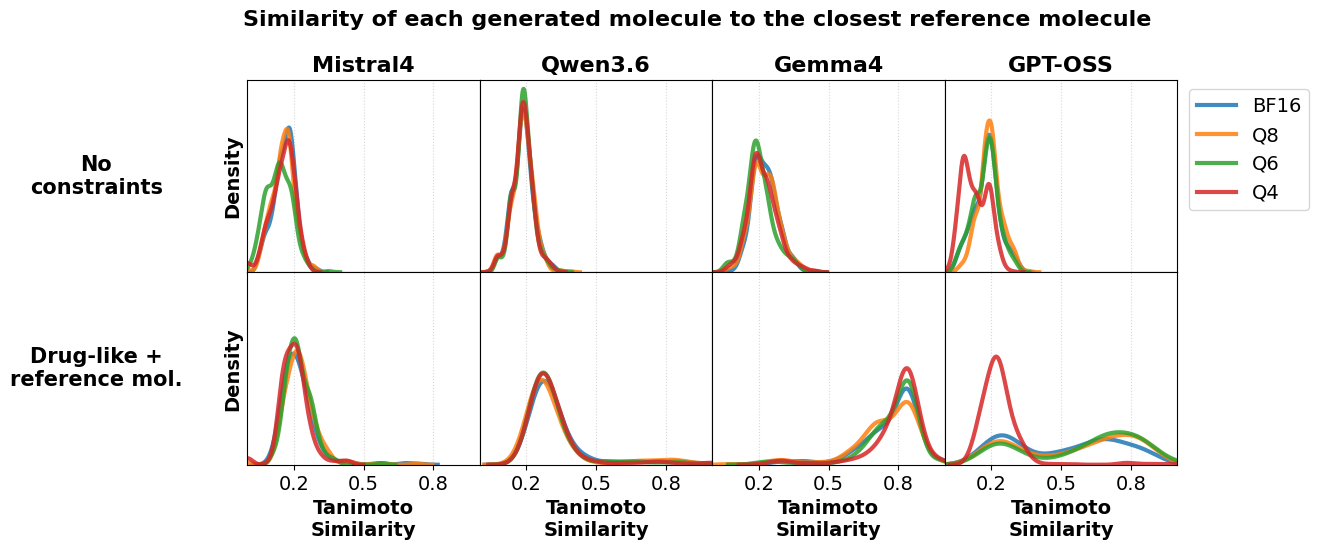

In [161]:
fig, ax = plt.subplots(2, 4, figsize=(12, 5), sharey=True, sharex=True)
fig.suptitle('Similarity of each generated molecule to the closest reference molecule\n\n', fontsize=16, fontweight='bold', y=1.02)

i=0
for model,label in zip(lst_models, lst_models_labels):
    if i==len(lst_models)-1:
        show_legend = True
    else:
        show_legend = False
        
    plot_data_kde(df_task1, model, label, stat='sim max', ax=ax[0][i], show_legend=show_legend, style='-')
    plot_data_kde(df_task2, model, label, stat='sim max', ax=ax[1][i], show_legend=False, style='-')
    ax[0][i].set_title('\n'+label, loc='center', fontsize=16, fontweight='bold')#, pad=4)

    i+=1

ax[0,0].yaxis.get_label().set_visible(True)
ax[1,0].yaxis.get_label().set_visible(True)

ax[0, 0].annotate('No\nconstraints', xy=(-0.65, 0.5), xycoords='axes fraction',
                  fontsize=15, fontweight='bold', rotation=0, ha='center', va='center')

ax[1, 0].annotate('Drug-like +\nreference mol.', xy=(-0.65, 0.5), xycoords='axes fraction',
                  fontsize=15, fontweight='bold', rotation=0, ha='center', va='center')

#plt.tight_layout()
fig.subplots_adjust(wspace=0.0, hspace=0)

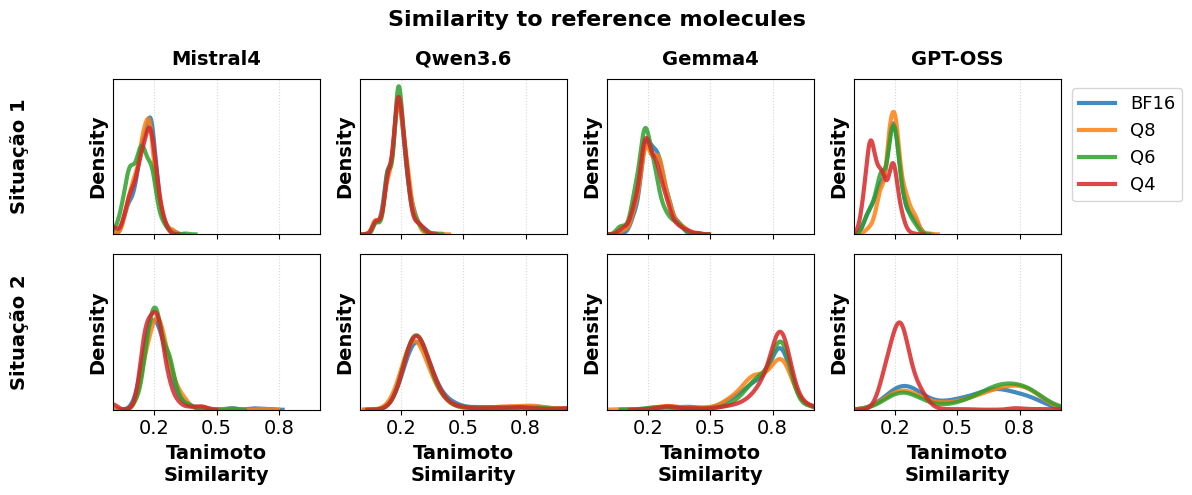

In [92]:
fig, ax = plt.subplots(2, 4, figsize=(12, 5), sharey=True, sharex=True)
fig.suptitle('Similarity to reference molecules', fontsize=16, fontweight='bold', y=0.98)

for i, (model, label) in enumerate(zip(lst_models, lst_models_labels)):
    show_legend = (i == len(lst_models) - 1)
        
    plot_data_kde(df_task1, model, label, stat='sim max', ax=ax[0][i], show_legend=show_legend)
    plot_data_kde(df_task2, model, label, stat='sim max', ax=ax[1][i], show_legend=False)
    
    ax[0][i].set_title(label, fontsize=14, fontweight='bold', pad=10)

# Adiciona os rótulos das situações à esquerda da 1ª coluna de cada linha
ax[0, 0].annotate('Situação 1', xy=(-0.45, 0.5), xycoords='axes fraction',
                  fontsize=14, fontweight='bold', rotation=90, ha='center', va='center')

ax[1, 0].annotate('Situação 2', xy=(-0.45, 0.5), xycoords='axes fraction',
                  fontsize=14, fontweight='bold', rotation=90, ha='center', va='center')

plt.tight_layout()
plt.show()

In [ ]:
def plot_data_histogram(df, stat, xlim=[0,1], bins = 15):
    tmp = df.groupby(['model','quantization'])[stat].sum()

    fig, ax = plt.subplots(len(lst_models), 1, figsize=(8, 8), sharey=True, sharex=True)
    for i,m in enumerate(lst_models):
        ax[i].set_xlim(xlim)
        ax[i].tick_params(axis='y', labelsize=14)
        for q in ['BF16', 'Q8', 'Q6', 'Q4']:
            ax[i].hist(tmp.loc[tmp.index==(m, q)], label=f'{m} {q}', bins=bins, range=xlim, alpha=0.9, histtype='step', linewidth=2, density=True)
            ax[i].legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
            ax[i].set_ylabel('Density', fontsize=15, fontweight='bold')

    ax[i].set_xlabel('Tanimoto Similarity', fontsize=15, fontweight='bold')
    plt.subplots_adjust(hspace=0)
    ax[i].tick_params(axis='x', labelsize=14)
    #plt.tight_layout()
    plt.show()


In [ ]:
def plot_data_histogram(df, stat, xlim=[0,1], bins = 15):
    tmp = df.groupby(['model','quantization'])[stat].sum()

    fig, ax = plt.subplots(len(lst_models), 1, figsize=(8, 8), sharey=True, sharex=True)
    for i,m in enumerate(lst_models):
        ax[i].set_xlim(xlim)
        ax[i].tick_params(axis='y', labelsize=14)
        for q in ['BF16', 'Q8', 'Q6', 'Q4']:
            ax[i].hist(tmp.loc[tmp.index==(m, q)], label=f'{m} {q}', bins=bins, range=xlim, alpha=0.9, histtype='step', linewidth=2, density=True)
            ax[i].legend(bbox_to_anchor=(1.00, 1.00), loc="upper left", fontsize=15)
            ax[i].set_ylabel('Density', fontsize=15, fontweight='bold')

    ax[i].set_xlabel('Tanimoto Similarity', fontsize=15, fontweight='bold')
    plt.subplots_adjust(hspace=0)
    ax[i].tick_params(axis='x', labelsize=14)
    #plt.tight_layout()
    plt.show()


In [16]:
def calc_umap_all(df, n_neighbors=15, min_dist=0.1, prompt=True):


    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=min_dist,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )

    df_tmp = df.groupby(['model', 'quantization'])['valid smiles'].sum()

    if prompt:
        lst_smi = lst_smiles_prompt.copy()
        lst_labels = ['prompt'] * len(lst_smiles_prompt)
    else:
        lst_smi = []
        lst_labels = []

    for q in lst_quants:
        for m in lst_models:
            tmp = df_tmp.loc[df_tmp.index==(m, q)].tolist()[0]
            lst_smi += tmp
            lst_labels += [(m,q)] * len(tmp)
            
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]

    embedding = reducer.fit_transform(lst_fps)
    df_umap = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
    df_umap['index'] = lst_labels
    df_umap = df_umap.set_index('index')


    return df_umap



In [17]:
def calc_umap_quant(df, n_neighbors=15, min_dist=0.1, prompt=True):

    df_tmp = df.groupby(['model', 'quantization'])['valid smiles'].sum()


    dfs = {}
    for q in lst_quants:
        dfs[q] = {}
        if prompt:
            lst_smi = lst_smiles_prompt.copy()
            lst_labels = ['prompt'] * len(lst_smiles_prompt)
        else:
            lst_smi = []
            lst_labels = []

        for m in lst_models:
            lst_smi_model = df_tmp.loc[df_tmp.index==(m, q)].tolist()[0]
            lst_smi += lst_smi_model
            lst_labels += [m] * len(lst_smi_model)

        lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
        lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]

        reducer = umap.UMAP(
            n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
            min_dist=min_dist,      # Controla o quão agrupados os pontos ficam no gráfico
            metric='jaccard',  # Ideal para fingerprints binários
            random_state=42    # Para reprodutibilidade
        )

        embedding = reducer.fit_transform(lst_fps)
        df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
        df['model'] = lst_labels
        df['quantization'] = q
        dfs[q] = df.copy()

    df_umap = pd.concat(dfs, ignore_index=True)
    df_umap = df_umap.set_index(['model', 'quantization'])
    return df_umap

In [18]:
def calc_umap_fit_prompt(df, n_neighbors=15, min_dist=0.1):


    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=min_dist,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )

    lst_smi = lst_smiles_prompt.copy()
    lst_labels = ['prompt'] * len(lst_smiles_prompt)
    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]

    embedding_ref = reducer.fit_transform(lst_fps)
    df_umap_ref = pd.DataFrame(embedding_ref, columns=['UMAP_1', 'UMAP_2'])
    df_umap_ref['index'] = lst_labels
    df_umap_ref = df_umap_ref.set_index('index')

    df_tmp = df.groupby(['model', 'quantization'])['valid smiles'].sum()
    lst_smi = []
    lst_labels = []
    for q in lst_quants:
        for m in lst_models:
            tmp = df_tmp.loc[df_tmp.index==(m, q)].tolist()[0]
            lst_smi += tmp
            lst_labels += [(m,q)] * len(tmp)

    lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
    lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]
    embedding_mols = reducer.transform(lst_fps)
    df_umap = pd.DataFrame(embedding_mols, columns=['UMAP_1', 'UMAP_2'])
    df_umap['index'] = lst_labels
    df_umap = df_umap.set_index('index')

    df_umap_final = pd.concat([df_umap_ref, df_umap])
    
    return df_umap_final



In [19]:
def plot_umap(df_umap, prompt=False, split_prompt_by_quant=False):
    alpha=0.35
    s=10

    

    d_xy = {'BF16':(0,0), 'Q8':(1,0), 'Q6':(0,1), 'Q4':(1,1)}
    colors = plt.cm.tab10.colors 

    fig, ax = plt.subplots(2,2, figsize=(12, 10))#, sharex=True, sharey=True)
    for q in lst_quants:
        i = d_xy[q]
        ax[i].set_title(q, fontsize=20, fontweight='bold')
        ax[i].grid(True, linestyle='--', alpha=0.3)
        ax[i].tick_params(axis='y', labelsize=16)
        ax[i].tick_params(axis='x', labelsize=16)

        
        if q in ['Q8', 'Q4']:
            ax[i].set_xlabel('UMAP 2', fontsize=18, fontweight='bold')
        if q in ['BF16', 'Q8']:
            ax[i].set_ylabel('UMAP 1', fontsize=18, fontweight='bold')

        if prompt:
            lst_tmp = ['prompt']+lst_models
        else:
            lst_tmp = lst_models.copy()

        for n,m in enumerate(lst_tmp):
            x = df_umap.loc[df_umap.index==(m,q)]['UMAP_1']
            y = df_umap.loc[df_umap.index==(m,q)]['UMAP_2']
            if (m=='prompt') and (split_prompt_by_quant==False):
                x = df_umap.loc[df_umap.index=='prompt']['UMAP_1']
                y = df_umap.loc[df_umap.index=='prompt']['UMAP_2']
            l = m
            if m == 'prompt':
                ax[i].scatter(x=x, y=y, label='prompt', alpha=1.00, s=50, color='black', linewidths=1.5, facecolors='none', zorder=10)
            else:
                if prompt:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.40, s=20, color=colors[n-1], linewidths=1.5, facecolors=colors[n-1])
                else:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.40, s=20, color=colors[n], linewidths=1.5, facecolors=colors[n])

    handles, labels = ax[(0,0)].get_legend_handles_labels()
    if prompt:
        labels = ['Prompt']
    else:
        labels = []
    labels += lst_models_labels

    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=18, frameon=True)
    #ax[i].set_xlim([-7,16])
    #ax[i].set_ylim([-2,15])
    
    plt.tight_layout()
    plt.show()

In [20]:
def plot_umap_grid(df_umap, prompt=True):
    #colors = plt.cm.tab10.colors
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

    if prompt:
        x_prompt = df_umap.loc[df_umap.index=='prompt']['UMAP_1']
        y_prompt = df_umap.loc[df_umap.index=='prompt']['UMAP_2']

    fig, ax = plt.subplots(4,4, figsize=(10, 8), sharex=True, sharey=True)

    handles = []
    for i_m, m in enumerate(lst_models):
        for i_q, q in enumerate(lst_quants):
            
            if i_q == 0:
                ax[i_q][i_m].set_title(lst_models_labels[i_m], fontsize=16, fontweight='bold')
            ax[i_q][i_m].grid(True, linestyle='--', alpha=0.3)
            ax[i_q][i_m].tick_params(axis='y', labelsize=13)
            ax[i_q][i_m].tick_params(axis='x', labelsize=13)
            if i_m == 0:
                ax[i_q][i_m].set_ylabel('UMAP 2', fontsize=14, fontweight='bold')
                

            if i_q == 3:
                ax[i_q][i_m].set_xlabel('UMAP 1', fontsize=14, fontweight='bold')

            x = df_umap.loc[df_umap.index==(m,q)]['UMAP_1']
            y = df_umap.loc[df_umap.index==(m,q)]['UMAP_2']

            #ax[i_q][i_m].scatter(x=x, y=y, label=m, alpha=0.40, s=20, color=colors[i_m-1], linewidths=1.5, facecolors=colors[i_m-1])
            #ax[i_q][i_m].scatter(x=x_prompt, y=y_prompt, label='prompt', alpha=1.00, s=20, color='black', linewidths=1.5, facecolors='none', zorder=10)

            
            plot_model = ax[i_q][i_m].scatter(x=x, y=y, label=m,
                alpha=0.25, s=20, color=colors[i_q], linewidths=1.5, facecolors=colors[i_q], zorder=10)
            
            if prompt:
                plot_prompt = ax[i_q][i_m].scatter(x=x_prompt, y=y_prompt, label='prompt',
                    alpha=0.60, s=60, color='black', linewidths=1.0, facecolors='none', zorder=5)
            

            if i_m == 0:
                if prompt:
                    if i_q == 0:
                        handles.append(plot_prompt)
                handles.append(plot_model)

    if prompt:
        lst_labels = ['Prompt']+lst_quants
    else:
        lst_labels = lst_quants
        
    leg = fig.legend(handles, lst_labels, loc='center left', bbox_to_anchor=(0.9, 0.78), fontsize=14, frameon=True)
    for handle in leg.legend_handles:
        handle.set_alpha(1.0)
    
    #plt.tight_layout()
    fig.subplots_adjust(wspace=0.0, hspace=0.0)
    plt.show()

In [21]:
def plot_umap_line(df_umap, prompt=False, split_prompt_by_quant=False):
    alpha=0.35
    s=10

    #d_xy = {'BF16':(0,0), 'Q8':(1,0), 'Q6':(0,1), 'Q4':(1,1)}
    #d_xy = {'BF16':0, 'Q8':1, 'Q6':2, 'Q4':3}
    colors = plt.cm.tab10.colors 

    fig, ax = plt.subplots(1,4, figsize=(13, 4), sharex=True, sharey=True)
    for i,q in enumerate(lst_quants):
        #i = d_xy[q]
        ax[i].set_title(q, fontsize=20, fontweight='bold')
        ax[i].grid(True, linestyle='--', alpha=0.3)
        ax[i].tick_params(axis='y', labelsize=16)
        ax[i].tick_params(axis='x', labelsize=16)
        ax[i].set_xlabel('UMAP 1', fontsize=18, fontweight='bold')
        if i==0:
            ax[i].set_ylabel('UMAP 2', fontsize=18, fontweight='bold')

        
        #if q in ['Q8', 'Q4']:
        #    ax[i].set_xlabel('UMAP 2', fontsize=18, fontweight='bold')
        #if q in ['BF16', 'Q8']:
        #    ax[i].set_ylabel('UMAP 1', fontsize=18, fontweight='bold')

        if prompt:
            lst_tmp = ['prompt']+lst_models
        else:
            lst_tmp = lst_models.copy()

        for n,m in enumerate(lst_tmp):
            x = df_umap.loc[df_umap.index==(m,q)]['UMAP_1']
            y = df_umap.loc[df_umap.index==(m,q)]['UMAP_2']
            if (m=='prompt') and (split_prompt_by_quant==False):
                x = df_umap.loc[df_umap.index=='prompt']['UMAP_1']
                y = df_umap.loc[df_umap.index=='prompt']['UMAP_2']
            l = m
            if m == 'prompt':
                ax[i].scatter(x=x, y=y, label='prompt', alpha=0.75, s=50, color='black', linewidths=1.0, facecolors='none', zorder=10)
            else:
                if prompt:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.40, s=15, color=colors[n-1], linewidths=1.5, facecolors=colors[n-1], zorder=5)
                else:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.40, s=15, color=colors[n], linewidths=1.5, facecolors=colors[n], zorder=5)

    handles, labels = ax[0].get_legend_handles_labels()
    if prompt:
        labels = ['Prompt']
    else:
        labels = []
    labels += lst_models_labels

    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=18, frameon=True)
    #ax[i].set_xlim([-7,16])
    #ax[i].set_ylim([-2,15])
    
    plt.tight_layout()
    plt.show()

In [22]:
# OLD
def umap_quant(df, n_neighbors=15, min_dist=0.1, prompt=True):

    df_tmp = df.groupby(['model', 'quantization'])['valid smiles'].sum()

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,    # Ajuste este valor (ex: 5 a 30). Como você tem poucas moléculas (69), um valor menor (ex: 5 ou 10) pode revelar mais estrutura local.
        min_dist=min_dist,      # Controla o quão agrupados os pontos ficam no gráfico
        metric='jaccard',  # Ideal para fingerprints binários
        random_state=42    # Para reprodutibilidade
    )


    dfs = {}
    for q in lst_quants:
        dfs[q] = {}
        if prompt:
            lst_smi = lst_smiles_prompt.copy()
            lst_labels = ['prompt'] * len(lst_smiles_prompt)
        else:
            lst_smi = []
            lst_labels = []

        for m in lst_models:
            lst_smi_model = df_tmp.loc[df_tmp.index==(m, q)].tolist()[0]
            lst_smi += lst_smi_model
            lst_labels += [m] * len(lst_smi_model)

        lst_mol = [Chem.MolFromSmiles(smi) for smi in lst_smi]
        lst_fps  = [AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048) for mol in lst_mol]

        embedding = reducer.fit_transform(lst_fps)
        df = pd.DataFrame(embedding, columns=['UMAP_1', 'UMAP_2'])
        df['model'] = lst_labels
        df['quantization'] = q
        dfs[q] = df.copy()

    df_umap = pd.concat(dfs, ignore_index=True)
    df_umap = df_umap.set_index(['model', 'quantization'])

    alpha=0.35
    s=10

    d_xy = {'BF16':(0,0), 'Q8':(1,0), 'Q6':(0,1), 'Q4':(1,1)}
    colors = plt.cm.tab10.colors 

    fig, ax = plt.subplots(2,2, figsize=(12, 10))#, sharex=True, sharey=True)
    for q in lst_quants:
        i = d_xy[q]
        ax[i].set_title(q, fontsize=20, fontweight='bold')
        ax[i].grid(True, linestyle='--', alpha=0.3)
        ax[i].tick_params(axis='y', labelsize=16)
        ax[i].tick_params(axis='x', labelsize=16)

        
        if q in ['Q8', 'Q4']:
            ax[i].set_xlabel('UMAP 2', fontsize=18, fontweight='bold')
        if q in ['BF16', 'Q8']:
            ax[i].set_ylabel('UMAP 1', fontsize=18, fontweight='bold')

        if prompt:
            lst_tmp = ['prompt']+lst_models
        else:
            lst_tmp = lst_models.copy()

        for n,m in enumerate(lst_tmp):
            x = df_umap.loc[df_umap.index==(m,q)]['UMAP_1']
            y = df_umap.loc[df_umap.index==(m,q)]['UMAP_2']
            l = m
            if m == 'prompt':
                ax[i].scatter(x=x, y=y, label='prompt', alpha=1.00, s=100, color='black', linewidths=1.5, facecolors='none')
            else:
                if prompt:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.25, s=40, color=colors[n-1])
                else:
                    ax[i].scatter(x=x, y=y, label=l, alpha=0.25, s=40, color=colors[n])

    handles, labels = ax[(0,0)].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=13, frameon=True)
    #ax[i].set_xlim([-7,16])
    #ax[i].set_ylim([-2,15])

    plt.tight_layout()
    plt.show()

    return df_umap

# **PROMPT**

In [23]:
lst_smiles_prompt = pd.read_csv('smiles_prompt.csv')['SMILES'].values.tolist()

n_smi_total = len(lst_smiles_prompt)
lst_valid_smi = validate_smiles(lst_smiles_prompt)
n_smi_valid = len(lst_valid_smi)
n_smi_druglike = len(smi_druglike(lst_valid_smi))
intdiv = calculate_intdiv(lst_valid_smi)

d_prompt = {'n_smi_total':n_smi_total, 'n_smi_valid':n_smi_valid,
            'n_smi_druglike' : n_smi_druglike,
            'n_smi_notdruglike' : n_smi_valid - n_smi_druglike,
            'intdiv':intdiv,
           }

d_prompt['pct_smi_valid']    = d_prompt['n_smi_valid']/d_prompt['n_smi_total']
d_prompt['pct_smi_druglike'] = d_prompt['n_smi_druglike']/d_prompt['n_smi_valid']
d_prompt['pct_smi_notdruglike'] = d_prompt['n_smi_notdruglike']/d_prompt['n_smi_valid']


In [24]:
lst_smiles_prompt

['O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCCC4)=NC=C2C)=C1)(NC(C)(C)C)=O',
 'O=C(C1=CC=C(C(OC)=C1)NC2=NC=C(N(C3=O)C)C(N([C@@H]3CC)C(C)C)=N2)N[C@H]4CC[C@@H](CC4)N5CCN(CC5)CC6CC6',
 'OCCOC1=CC2=C(N=CN=C2NC3=CC=CC(C#C)=C3)C=C1OCCOC',
 'O=C(NC1=C(C=C2C(C(NC3=CC=C(C(Cl)=C3)F)=NC=N2)=C1)OCCCN4CCOCC4)C=C',
 'O=C(C1=C(C)N(CC(C)(O)C)N(C2=CC=CC=C2)C1=O)NC3=NC=C(OC4=CC=NC5=CC(OC)=CC=C45)C=C3',
 'O=C(NC1=CC=C(C=C1F)OC2=CC(NC(N3CCC(CC3)N4CCN(CC4)C)=O)=NC=C2)C5(CC5)C(NC6=CC=C(C=C6)F)=O',
 'N#CC1=C(C2=CC(NC(/C=C/CN(C)C)=O)=C(OCC)C=C2N=C1)NC3=CC(Cl)=C(C=C3)F',
 'O=C(NC1=C(C=C2C(C(NC3=CC(Cl)=C(C=C3)F)=NC=N2)=C1)O[C@H]4CCOC4)/C=C/CN(C)C',
 'ClC1=C(C=CC(NC2=NC=NC3=C2C=C(C(OC)=C3)OCCCN4CCOCC4)=C1)F',
 'O/N=C1CCC2=CC(C3=C(NC(C4=CC=C(C=C4)OCCN(C)C)=N3)C5=CC=NC=C5)=CC=C/12',
 'FC(C(Cl)=CC=C1)=C1O[C@H](CC2)CC[C@@]2(C(O)=O)CC3=CC=CC(NC4=NC=CS4)=N3',
 'O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)N4CCN(CC4)C)=NC=C2C)=C1)(NC(C)(C)C)=O',
 'CN1CCN(C2=CC=C(C=C2)NC3=NC=C(C(OC4=CC(NC(C=C)=O)=CC=C4)=N3)Cl)CC1',
 'O=C(/C=C/CN1CCC

In [25]:
d_prompt

{'n_smi_total': 69,
 'n_smi_valid': 69,
 'n_smi_druglike': 69,
 'n_smi_notdruglike': 0,
 'intdiv': 0.8510483566601391,
 'pct_smi_valid': 1.0,
 'pct_smi_druglike': 1.0,
 'pct_smi_notdruglike': 0.0}

# **TASK1**

## 1. Load raw data

In [26]:
df_task1 = pd.read_csv('raw_data_task1.csv')
df_task1['replica'] = df_task1.groupby(['model', 'quantization']).cumcount() + 1 # annotates the replica number
df_task1['smiles'] = df_task1.apply(lambda x: load_smiles_list_to_df(df=x, path_smiles=path_smiles_task1), axis=1)
df_task1


,quantization,model,tokens_per_second,duration_min,replica,smiles
0,BF16,gpt-oss-120B,14.255372,8.306117,1,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O..."
1,BF16,gpt-oss-120B,14.344542,6.297450,2,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)..."
2,BF16,gpt-oss-120B,14.392826,3.095300,3,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C..."
3,BF16,gpt-oss-120B,14.016174,13.825083,4,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(..."
4,BF16,gpt-oss-120B,13.866866,11.298450,5,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, Cn..."
...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.576826,22.101167,21,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,..."
396,BF16,Mistral4-119B,4.576121,21.860533,22,"[CC1=CC=CC=C1C(=O)OCC, CC1(C)C2=CC=CC=C2C(=O)N..."
397,BF16,Mistral4-119B,4.598729,4.447450,23,"[CCOc1ccc2c(c1)C(=O)c1[nH]c3ccccc3c21c1ccccc1,..."
398,BF16,Mistral4-119B,4.597749,6.884150,24,[]


In [27]:
df_task1 = calculate_metrics(df_task1)
df_task1

,quantization,model,tokens_per_second,duration_min,replica,smiles,valid smiles,unique smiles,diff smiles,sim all,...,pct_smi_valid,pct_smi_invalid,pct_smi_duplicated,pct_smi_overlap,druglike smiles,n_smi_druglike,n_smi_notdruglike,pct_smi_druglike,pct_smi_notdruglike,intdiv
0,BF16,gpt-oss-120B,14.255372,8.306117,1,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...","[0.0875, 0.09473684210526316, 0.11764705882352...",...,0.850000,0.150000,0.0000,0.0,"[O=C(C)Oc1ccccc1C(=O)O, CN1C=NC2=C1C(=O)N(C(=O...",17,0,1.0,0.0,0.812533
1,BF16,gpt-oss-120B,14.344542,6.297450,2,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...","[0.05194805194805195, 0.06521739130434782, 0.0...",...,0.950000,0.050000,0.0000,0.0,"[CC(C)NCC(O)CO, c1ccccc1, c1ccncc1, c1cc(ccc1)...",19,0,1.0,0.0,0.838292
2,BF16,gpt-oss-120B,14.392826,3.095300,3,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...","[0.0875, 0.09473684210526316, 0.11764705882352...",...,1.000000,0.000000,0.0000,0.0,"[CC(=O)Oc1ccccc1C(=O)O, CC(C)CC1=CC=C(C=C1)C(C...",20,0,1.0,0.0,0.881253
3,BF16,gpt-oss-120B,14.016174,13.825083,4,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...","[0.10666666666666667, 0.08695652173913043, 0.1...",...,0.850000,0.150000,0.0000,0.0,"[CC(=O)NC1=CC=C(O)C=C1, CC(C)Cc1ccc(cc1)C(C)C(...",17,0,1.0,0.0,0.840247
4,BF16,gpt-oss-120B,13.866866,11.298450,5,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, Cn...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...","[0.15, 0.11224489795918367, 0.1571428571428571...",...,0.950000,0.050000,0.0000,0.0,"[CC(C)NCC(O)COc1ccccc1, c1ccc(Cl)cc1C(=O)O, c1...",19,0,1.0,0.0,0.890145
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.576826,22.101167,21,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...","[0.10666666666666667, 0.08695652173913043, 0.1...",...,0.761905,0.238095,0.0000,0.0,"[CC(=O)Nc1ccc(O)cc1, CC(=O)OC1=CC=CC=C1C(=O)O,...",16,0,1.0,0.0,0.867857
396,BF16,Mistral4-119B,4.576121,21.860533,22,"[CC1=CC=CC=C1C(=O)OCC, CC1(C)C2=CC=CC=C2C(=O)N...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...","[0.12987012987012986, 0.10638297872340426, 0.1...",...,0.842105,0.157895,0.0625,0.0,"[CC1=CC=CC=C1C(=O)OCC, C1=CC=CC=C1C(=O)NCC2=CC...",16,0,1.0,0.0,0.795691
397,BF16,Mistral4-119B,4.598729,4.447450,23,"[CCOc1ccc2c(c1)C(=O)c1[nH]c3ccccc3c21c1ccccc1,...","[CC(=O)Nc1ccc(O)cc1C(=O)O, Cc1ccccc1N2C(=O)CCC...","[CC(=O)Nc1ccc(O)cc1C(=O)O, Cc1ccccc1N2C(=O)CCC...","[CC(=O)Nc1ccc(O)cc1C(=O)O, Cc1ccccc1N2C(=O)CCC...","[0.08536585365853659, 0.11578947368421053, 0.0...",...,0.952381,0.047619,0.1000,0.0,"[CC(=O)Nc1ccc(O)cc1C(=O)O, Cc1ccccc1N2C(=O)CCC...",20,0,1.0,0.0,0.763079
398,BF16,Mistral4-119B,4.597749,6.884150,24,[],[],[],[],[],...,0.000000,0.000000,0.0000,0.0,[],0,0,0.0,0.0,NaN


In [28]:
d_stats_task1 = calc_stats(df_task1)
d_stats_task1

{'Mistral4-119B': {'BF16': {'tokens_per_second': {'avg': 4.433329837339215,
    'std': 0.34672531151621405,
    'med': 4.576825955601774},
   'duration_min': {'avg': 13.764698666666666,
    'std': 7.617711911690545,
    'med': 12.62805},
   'pct_smi_valid': {'avg': 0.76065664160401,
    'std': 0.29830643146192304,
    'med': 0.8421052631578947},
   'pct_smi_invalid': {'avg': 0.11934335839598997,
    'std': 0.09392851883504014,
    'med': 0.15},
   'pct_smi_duplicated': {'avg': 0.020254385964912282,
    'std': 0.040947103145109034,
    'med': 0.0},
   'pct_smi_overlap': {'avg': 0.0, 'std': 0.0, 'med': 0.0},
   'pct_smi_druglike': {'avg': 0.8773333333333333,
    'std': 0.3309246305597562,
    'med': 1.0},
   'pct_smi_notdruglike': {'avg': 0.0026666666666666666,
    'std': 0.013333333333333334,
    'med': 0.0},
   'intdiv': {'avg': 0.8433297687017134,
    'std': 0.0513034336171945,
    'med': 0.8570633415280835},
   'sim all avg': {'avg': 0.07327577977919676,
    'std': 0.0321523295279927

In [29]:
min_dist = 0.3
n_neighbors = 10

df_task1_umap_all = calc_umap_all(df=df_task1, n_neighbors=n_neighbors, min_dist=min_dist, prompt=False)

# TASK 2

# 1. Load raw data

In [30]:
df_task2 = pd.read_csv('raw_data_task2.csv')
df_task2['replica'] = df_task2.groupby(['model', 'quantization']).cumcount() + 1 # annotates the replica number
df_task2['smiles'] = df_task2.apply(lambda x: load_smiles_list_to_df(df=x, path_smiles=path_smiles_task2), axis=1)
df_task2


,quantization,model,tokens_per_second,duration_min,replica,smiles
0,BF16,gpt-oss-120B,14.209755,26.579133,1,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
1,BF16,gpt-oss-120B,14.065747,36.731050,2,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...
2,BF16,gpt-oss-120B,14.298367,19.241883,3,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...
3,BF16,gpt-oss-120B,14.131008,36.153983,4,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
4,BF16,gpt-oss-120B,14.098691,30.805183,5,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...
...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.709737,8.291433,21,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...
396,BF16,Mistral4-119B,4.711069,8.434183,22,[CN1CCN(C2=CC=C(Cl)C=C2)C3=CC=C(C=C3)NC(C4)C(=...
397,BF16,Mistral4-119B,4.605285,41.774433,23,"[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C..."
398,BF16,Mistral4-119B,4.720910,3.344550,24,"[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC..."


In [31]:
df_task2 = calculate_metrics(df_task2)
df_task2

,quantization,model,tokens_per_second,duration_min,replica,smiles,valid smiles,unique smiles,diff smiles,sim all,...,pct_smi_valid,pct_smi_invalid,pct_smi_duplicated,pct_smi_overlap,druglike smiles,n_smi_druglike,n_smi_notdruglike,pct_smi_druglike,pct_smi_notdruglike,intdiv
0,BF16,gpt-oss-120B,14.209755,26.579133,1,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,"[0.8695652173913043, 0.18699186991869918, 0.20...",...,0.950000,0.050000,0.0,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,17,2,0.894737,0.105263,0.813654
1,BF16,gpt-oss-120B,14.065747,36.731050,2,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,"[0.1744186046511628, 0.12380952380952381, 0.12...",...,0.750000,0.250000,0.0,0.0,[O=C(Nc1ccc(Cl)cc1)Nc2nc(Nc3ccccc3)nc(Nc4ccc(F...,15,0,1.000000,0.000000,0.848630
2,BF16,gpt-oss-120B,14.298367,19.241883,3,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,"[0.2111111111111111, 0.125, 0.1529411764705882...",...,0.900000,0.100000,0.0,0.0,[O=S(=O)(N(C)C1=CC=CC=C1)C2=CC=CC(NC(=O)C3=CC=...,18,0,1.000000,0.000000,0.823012
3,BF16,gpt-oss-120B,14.131008,36.153983,4,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,"[0.72, 0.21666666666666667, 0.2040816326530612...",...,1.000000,0.000000,0.0,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,17,3,0.850000,0.150000,0.805525
4,BF16,gpt-oss-120B,14.098691,30.805183,5,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,"[0.6710526315789473, 0.19008264462809918, 0.20...",...,0.950000,0.050000,0.0,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(C=C3)OCCN4CCOCC4...,14,5,0.736842,0.263158,0.825582
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,BF16,Mistral4-119B,4.709737,8.291433,21,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,"[0.6666666666666666, 0.15789473684210525, 0.19...",...,0.500000,0.500000,0.0,0.0,[O=S(C1=CC=CC(NC2=NC(NC3=CC=C(CC)C=C3)=NC=C2C)...,14,1,0.933333,0.066667,0.822359
396,BF16,Mistral4-119B,4.711069,8.434183,22,[CN1CCN(C2=CC=C(Cl)C=C2)C3=CC=C(C=C3)NC(C4)C(=...,"[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...","[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...","[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...","[0.1511627906976744, 0.16, 0.07317073170731707...",...,0.526316,0.473684,0.0,0.0,"[O=C(NC1=CC=C(C=C1)F)N2CCC(CC2)N3CCCCC3, CC1=C...",10,0,1.000000,0.000000,0.839137
397,BF16,Mistral4-119B,4.605285,41.774433,23,"[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...","[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...","[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...","[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...","[0.12987012987012986, 0.11827956989247312, 0.1...",...,0.150000,0.850000,0.0,0.0,"[O=C(NC1=CC=CC=C1)C2=NC=CC=N2, O=S(NC1=CC=CC=C...",3,0,1.000000,0.000000,0.787865
398,BF16,Mistral4-119B,4.720910,3.344550,24,"[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...","[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...","[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...","[CN1CCN(C2=CC=CC=C2)CCC1, N#CC1=CC=CC=C1NC2=CC...","[0.12987012987012986, 0.08333333333333333, 0.0...",...,0.894737,0.105263,0.0,0.0,"[CN1CCN(C2=CC=CC=C2)CCC1, N#CC

In [32]:
d_stats_task2 = calc_stats(df_task2)
d_stats_task2

{'Mistral4-119B': {'BF16': {'tokens_per_second': {'avg': 4.537699146271506,
    'std': 0.43879909588539384,
    'med': 4.7058953753537285},
   'duration_min': {'avg': 10.373424666666667,
    'std': 10.466659569543904,
    'med': 6.25005},
   'pct_smi_valid': {'avg': 0.6161938178780284,
    'std': 0.32958396864123635,
    'med': 0.75},
   'pct_smi_invalid': {'avg': 0.3038061821219716,
    'std': 0.28739048245485804,
    'med': 0.21052631578947367},
   'pct_smi_duplicated': {'avg': 0.03125885792913657,
    'std': 0.06912282571513734,
    'med': 0.0},
   'pct_smi_overlap': {'avg': 0.0, 'std': 0.0, 'med': 0.0},
   'pct_smi_druglike': {'avg': 0.9173333333333333,
    'std': 0.2764054992217051,
    'med': 1.0},
   'pct_smi_notdruglike': {'avg': 0.0026666666666666666,
    'std': 0.013333333333333332,
    'med': 0.0},
   'intdiv': {'avg': 0.797974106671446,
    'std': 0.06224438034193706,
    'med': 0.8223586833517287},
   'sim all avg': {'avg': 0.10512567400505182,
    'std': 0.034907022945589

In [33]:
min_dist = 0.30
n_neighbors = 10

df_task2_umap_all = calc_umap_all(df=df_task2, n_neighbors=n_neighbors, min_dist=min_dist, prompt=True)
df_task2_umap_all

,UMAP_1,UMAP_2
index,,
prompt,8.056129,4.708014
prompt,24.069765,6.610836
prompt,13.684450,0.320632
prompt,-2.621862,2.467552
prompt,-2.403235,8.818425
...,...,...
"(gpt-oss-120B, Q4)",13.267115,3.773283
"(gpt-oss-120B, Q4)",13.312427,3.850829
"(gpt-oss-120B, Q4)",13.282150,3.812513


---

# **TESTES** - TASK1

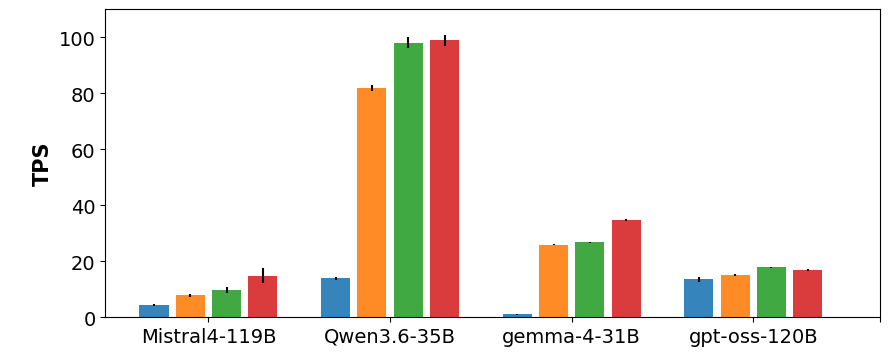

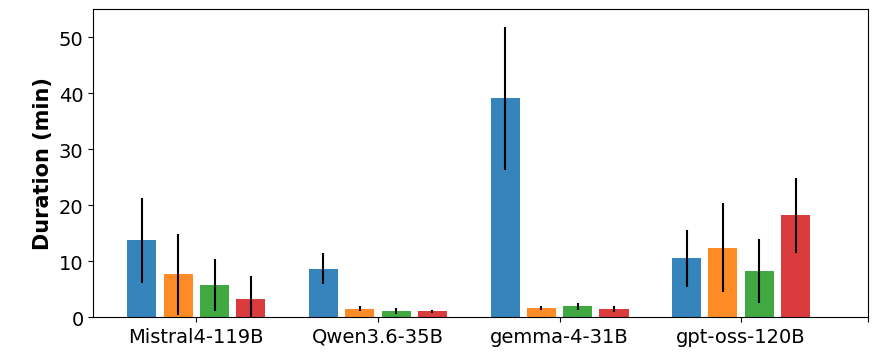

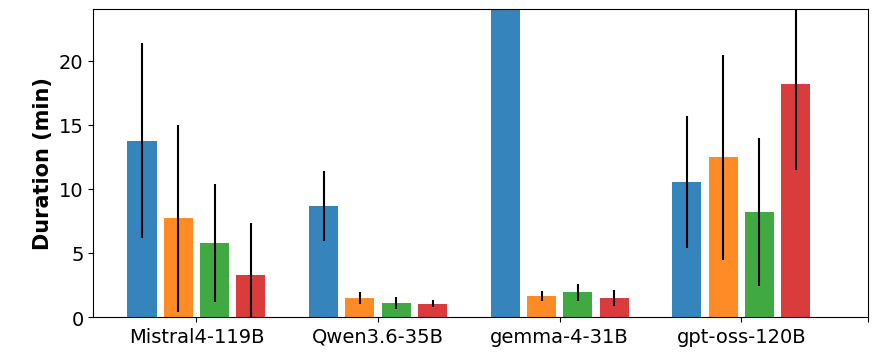

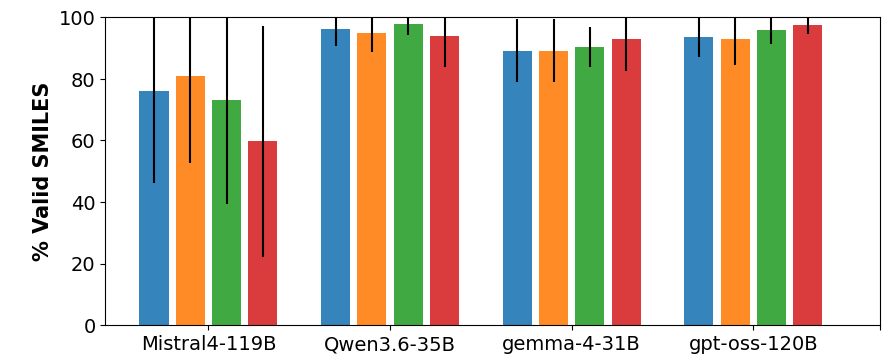

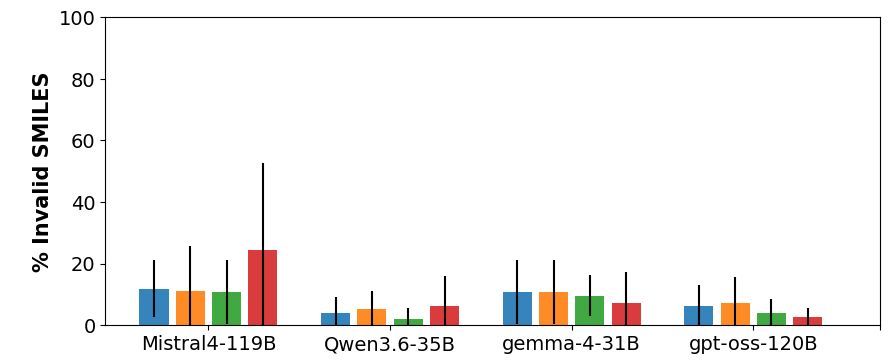

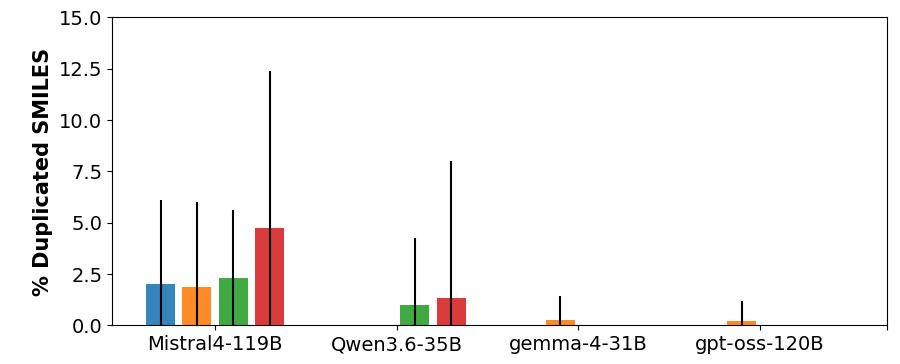

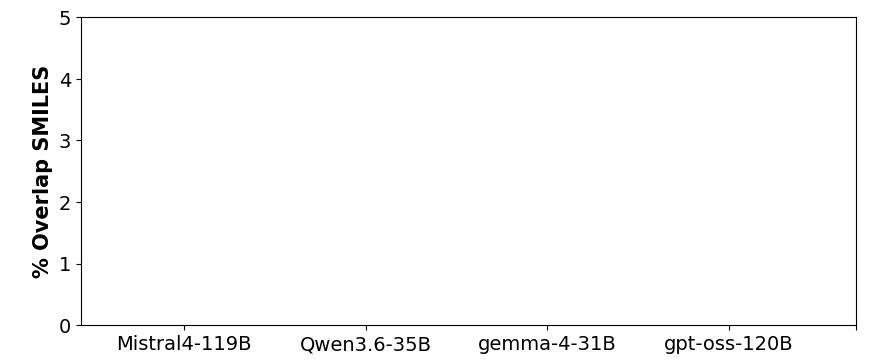

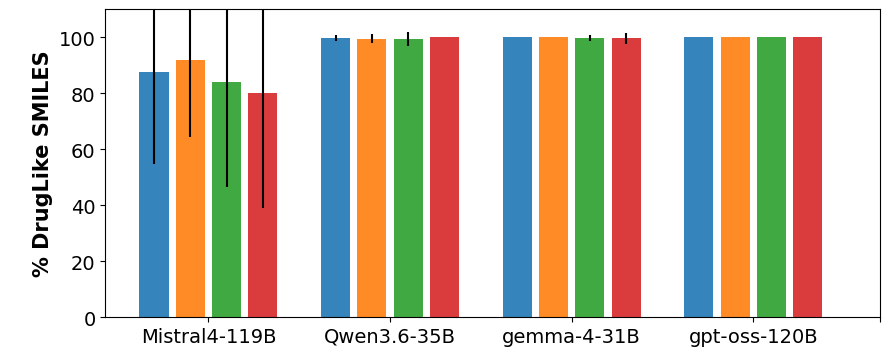

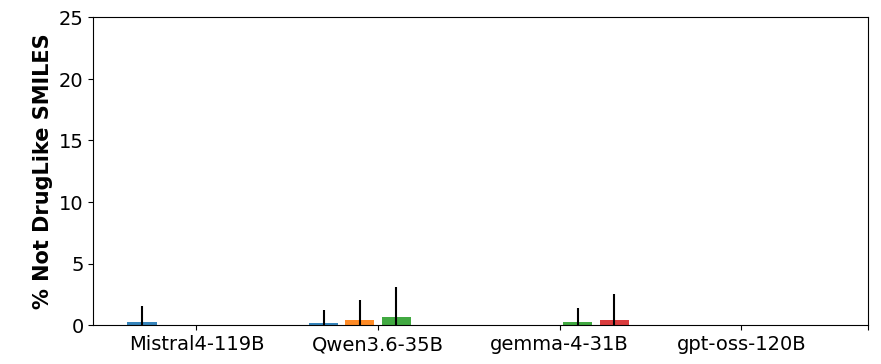

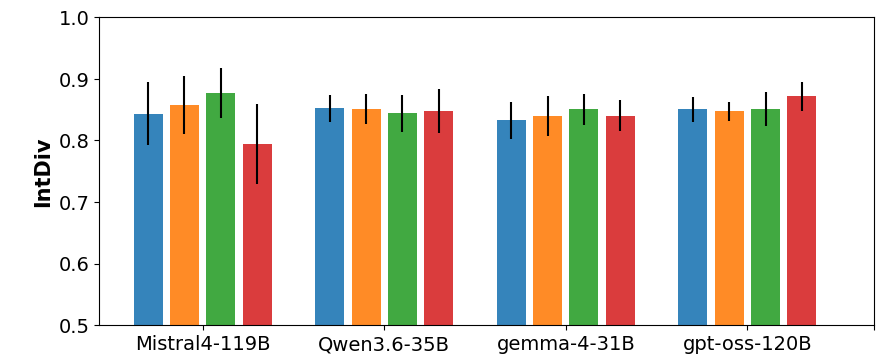

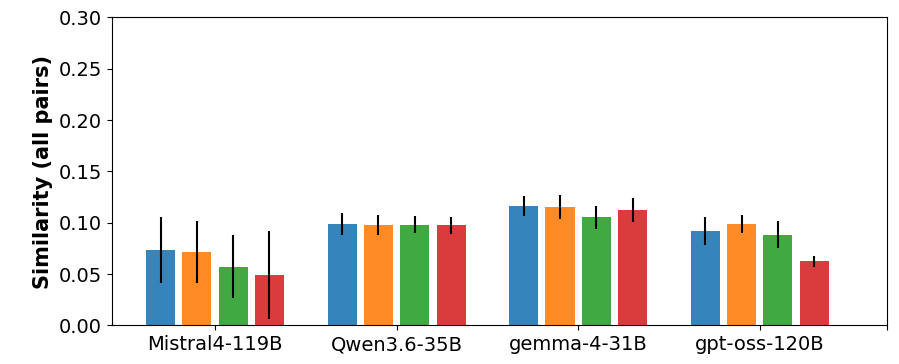

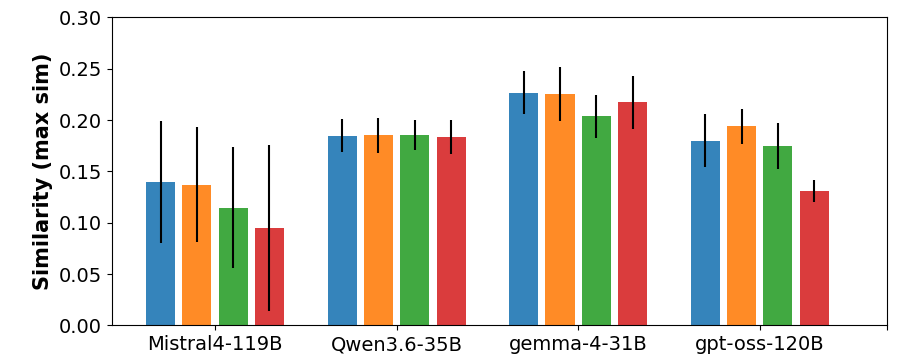

In [30]:
plot_data(d_stats=d_stats_task1, stat='tokens_per_second', ylabel='TPS'           , ylim=[0,110], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task1, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,55],  prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task1, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,24],  prompt_avg=None, prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task1, stat='pct_smi_valid',     ylabel='% Valid SMILES'      , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_invalid',   ylabel='% Invalid SMILES'    , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='pct_smi_duplicated',ylabel='% Duplicated SMILES' , ylim=[0,15],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_overlap',   ylabel='% Overlap SMILES'    , ylim=[0,5],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='pct_smi_druglike',     ylabel='% DrugLike SMILES', ylim=[0,110], prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task1, stat='pct_smi_notdruglike',  ylabel='% Not DrugLike SMILES', ylim=[0,25], prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task1, stat='intdiv',  ylabel='IntDiv', ylim=[0.5,1], prompt_avg=None, prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task1, stat='sim all avg',  ylabel='Similarity (all pairs)', ylim=[0,0.30], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task1, stat='sim max avg',  ylabel='Similarity (max sim)', ylim=[0,0.30], prompt_avg=None, prompt_std=0.0, scale=1)


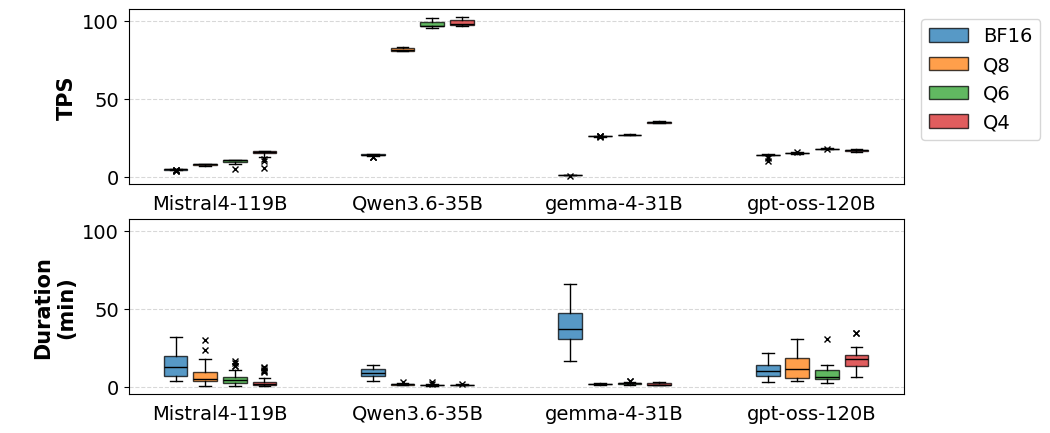

In [31]:
fig, ax = plt.subplots(2,1, figsize=(10, 5), sharey=True)
plot_data_boxplot(df_task1, 'tokens_per_second', ax=ax[0], ylabel='TPS', show_legend=True)
plot_data_boxplot(df_task1, 'duration_min',     ax=ax[1], ylabel='Duration\n(min)')

>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 0.3


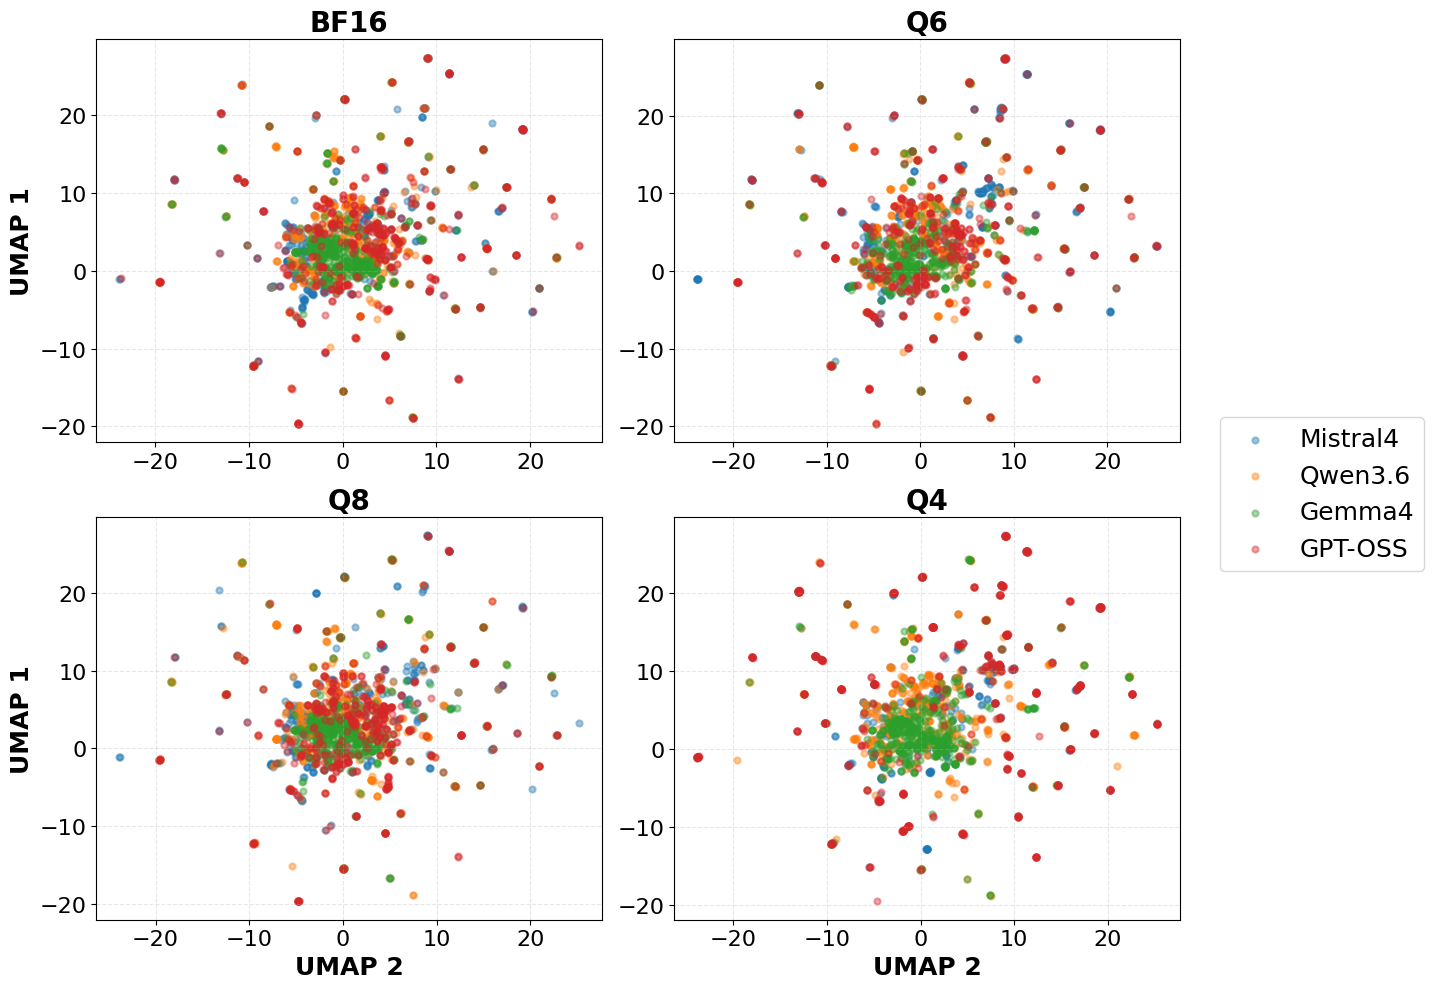

>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 0.6


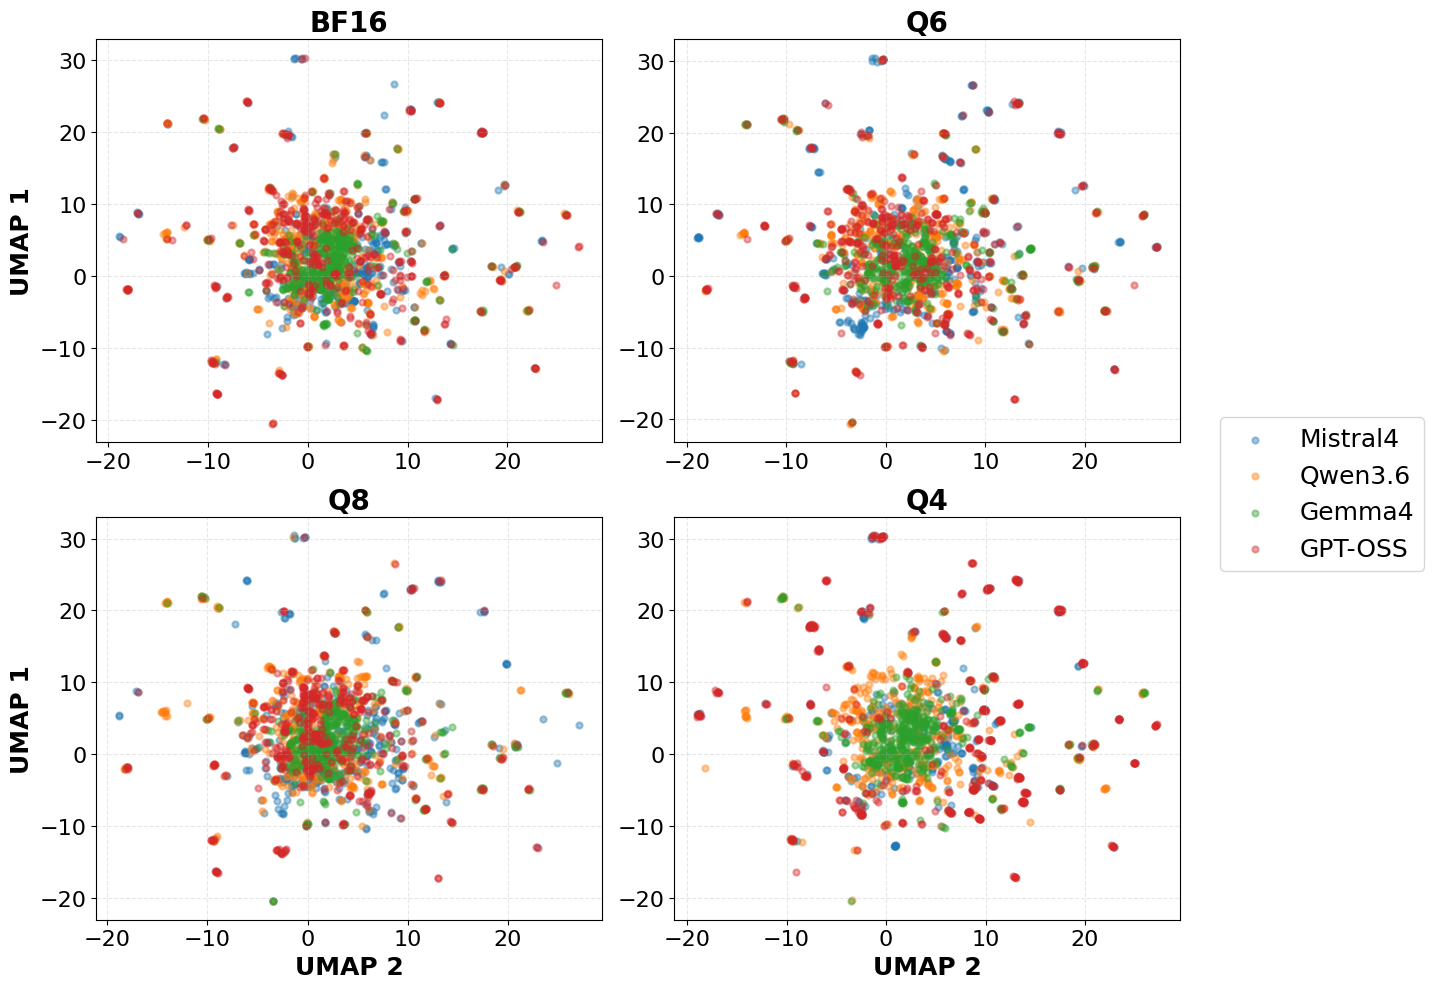

>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 1.0


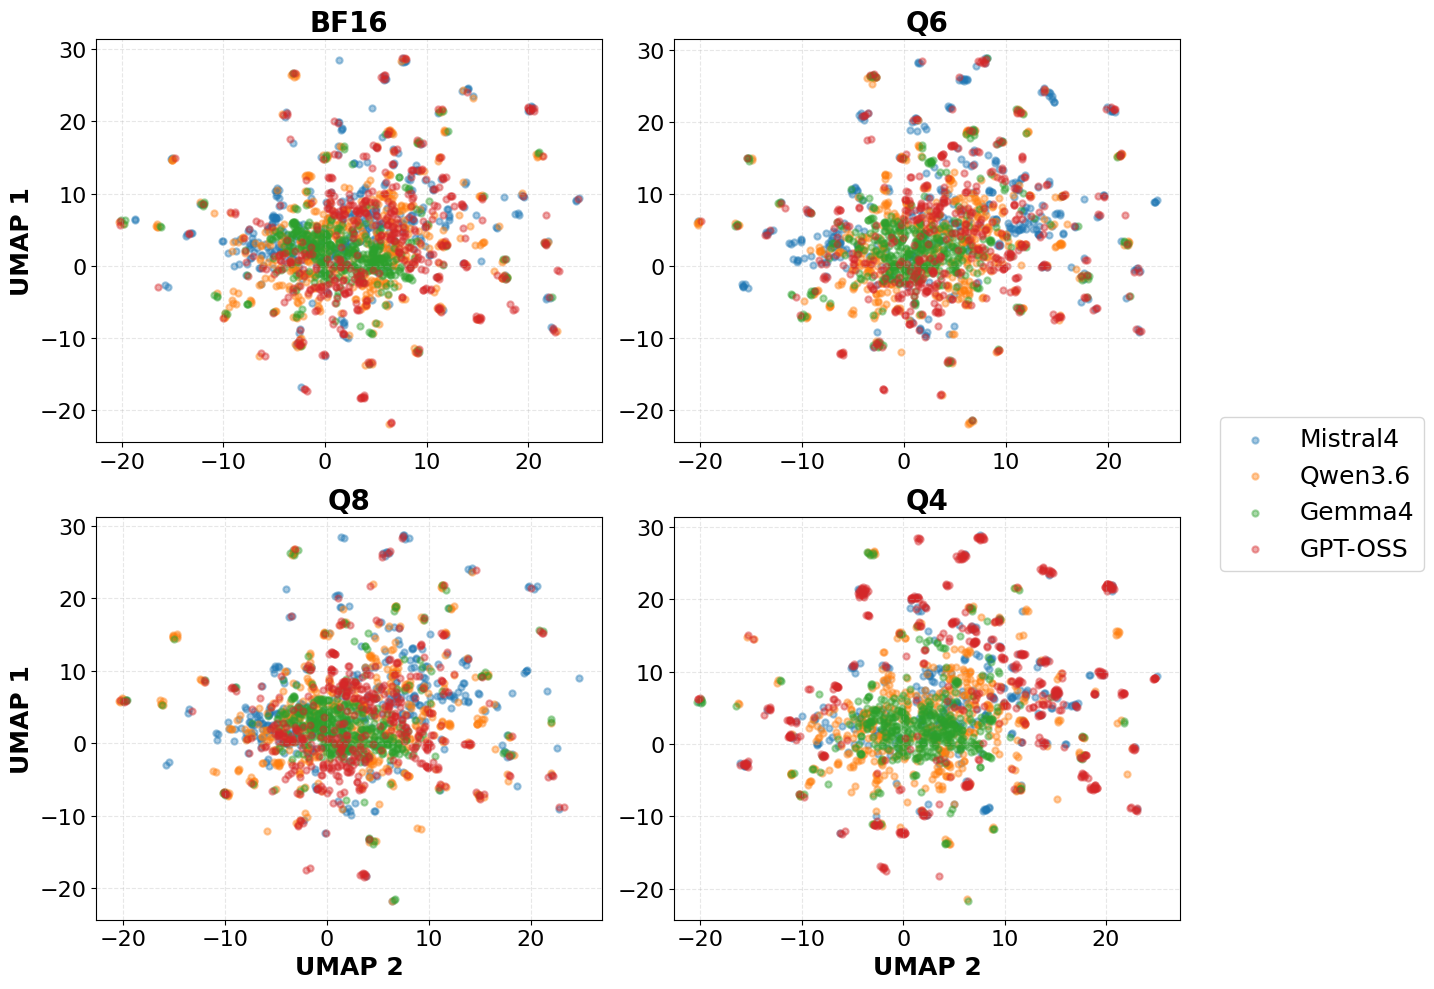

In [262]:
for min_dist in [0.3, 0.6, 1.0]:
    for n_neighbors in [10]:
        print('='*70)
        print('>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<')
        print('N_NEIGHBORS =', n_neighbors)
        print('MIN_DIST    =', min_dist)

        tmp = calc_umap_all(df=df_task1, n_neighbors=n_neighbors, min_dist=min_dist, prompt=False)
        plot_umap(tmp, prompt=False, split_prompt_by_quant=False)

# **TESTES** - TASK 2

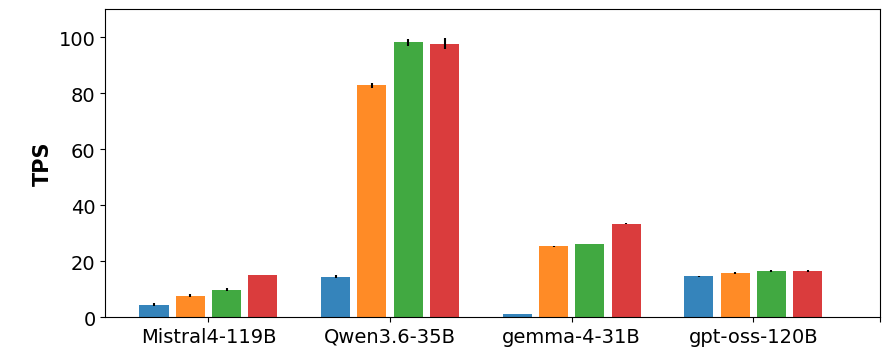

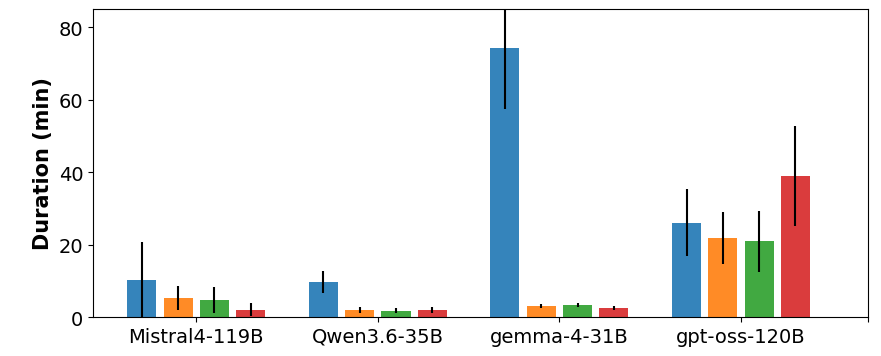

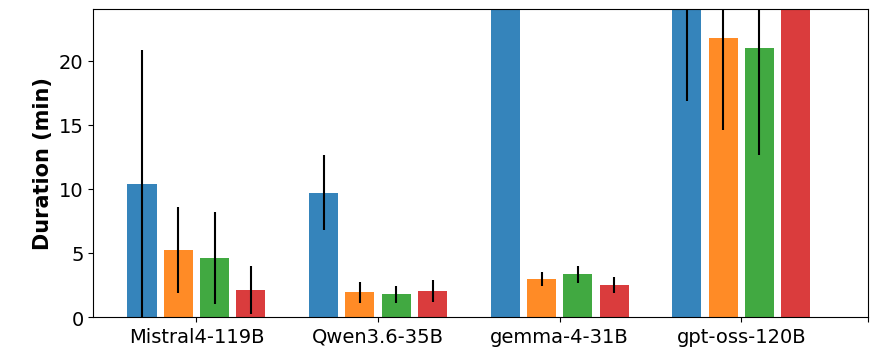

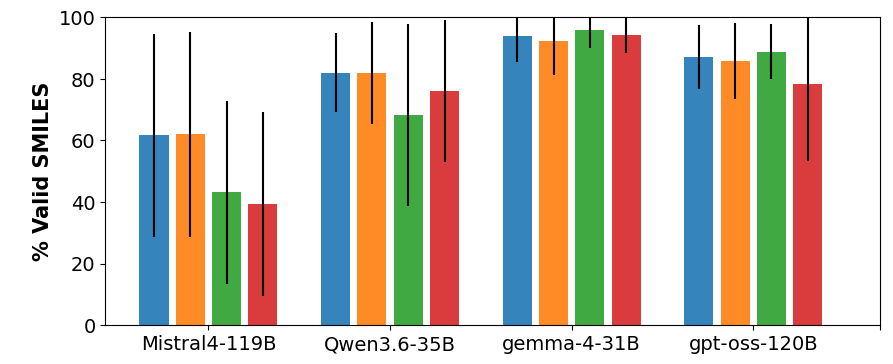

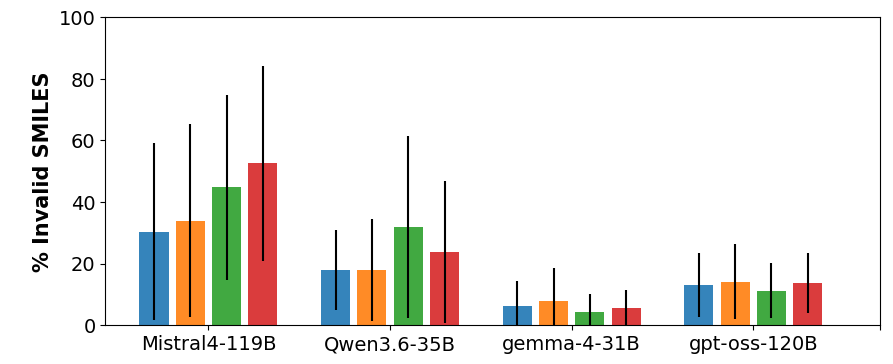

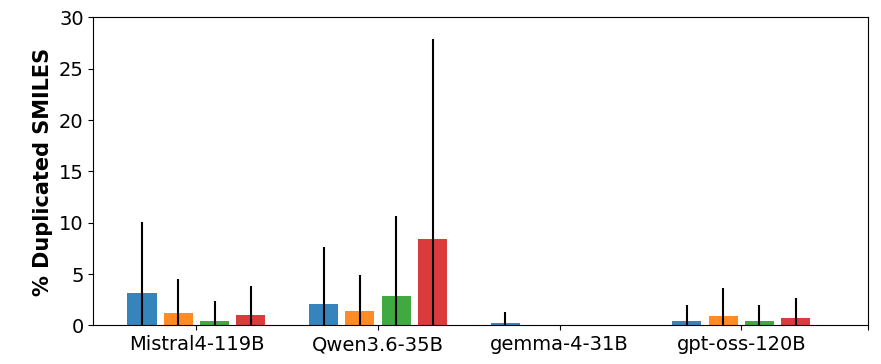

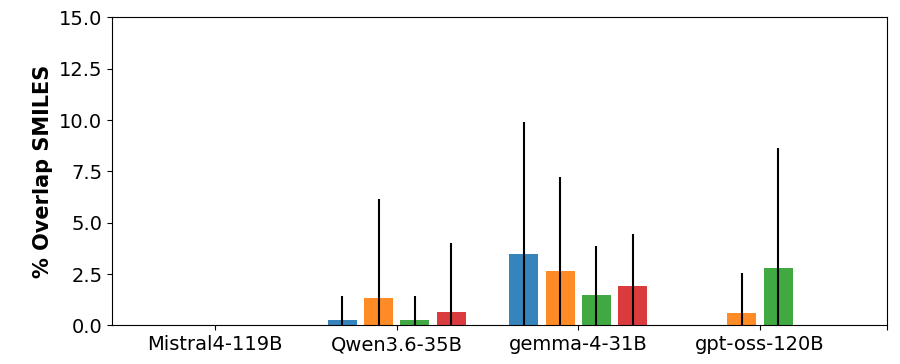

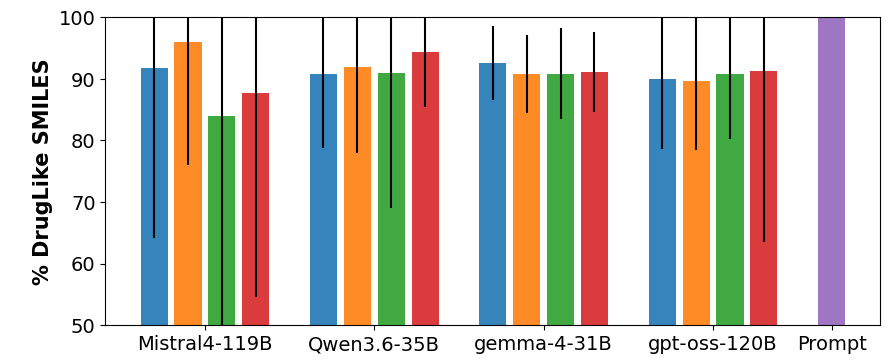

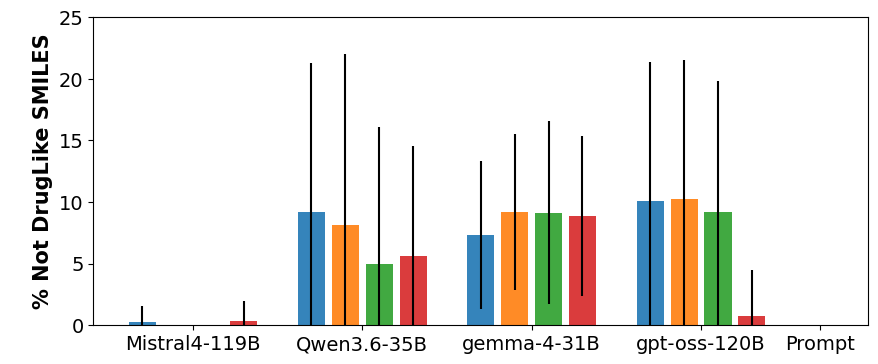

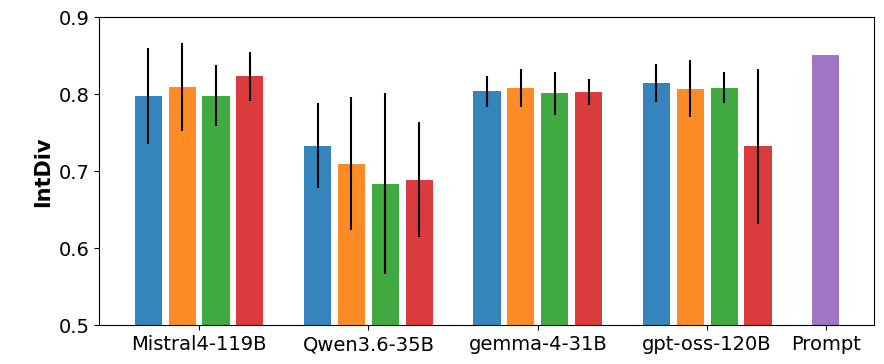

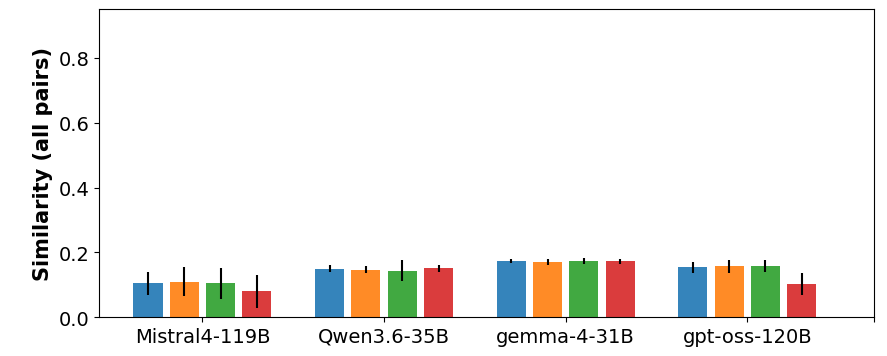

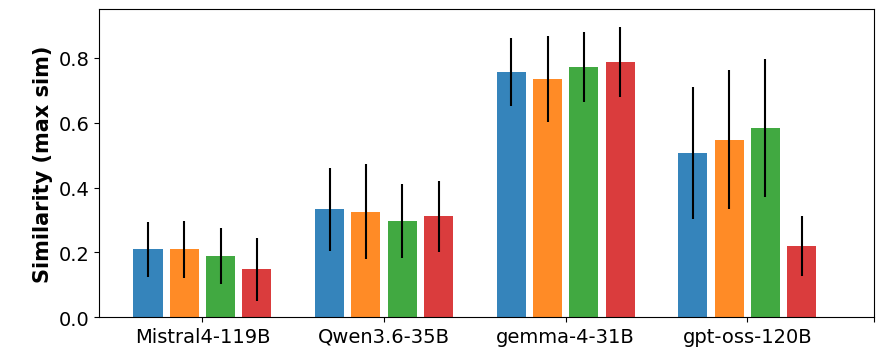

In [27]:
plot_data(d_stats=d_stats_task2, stat='tokens_per_second', ylabel='TPS'           , ylim=[0,110], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task2, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,85],  prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task2, stat='duration_min',      ylabel='Duration (min)'  , ylim=[0,24],  prompt_avg=None, prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task2, stat='pct_smi_valid',     ylabel='% Valid SMILES'      , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_invalid',   ylabel='% Invalid SMILES'    , ylim=[0,100],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_duplicated',ylabel='% Duplicated SMILES' , ylim=[0,30],  prompt_avg=None, prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_overlap',   ylabel='% Overlap SMILES'    , ylim=[0,15],  prompt_avg=None, prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task2, stat='pct_smi_druglike',     ylabel='% DrugLike SMILES', ylim=[50,100], prompt_avg=d_prompt['pct_smi_druglike'], prompt_std=0.0, scale=100)
plot_data(d_stats=d_stats_task2, stat='pct_smi_notdruglike',  ylabel='% Not DrugLike SMILES', ylim=[0,25], prompt_avg=d_prompt['pct_smi_notdruglike'], prompt_std=0.0, scale=100)

plot_data(d_stats=d_stats_task2, stat='intdiv',  ylabel='IntDiv', ylim=[0.5,0.9], prompt_avg=d_prompt['intdiv'], prompt_std=0.0, scale=1)

plot_data(d_stats=d_stats_task2, stat='sim all avg',  ylabel='Similarity (all pairs)', ylim=[0,0.95], prompt_avg=None, prompt_std=0.0, scale=1)
plot_data(d_stats=d_stats_task2, stat='sim max avg',  ylabel='Similarity (max sim)', ylim=[0,0.95], prompt_avg=None, prompt_std=0.0, scale=1)

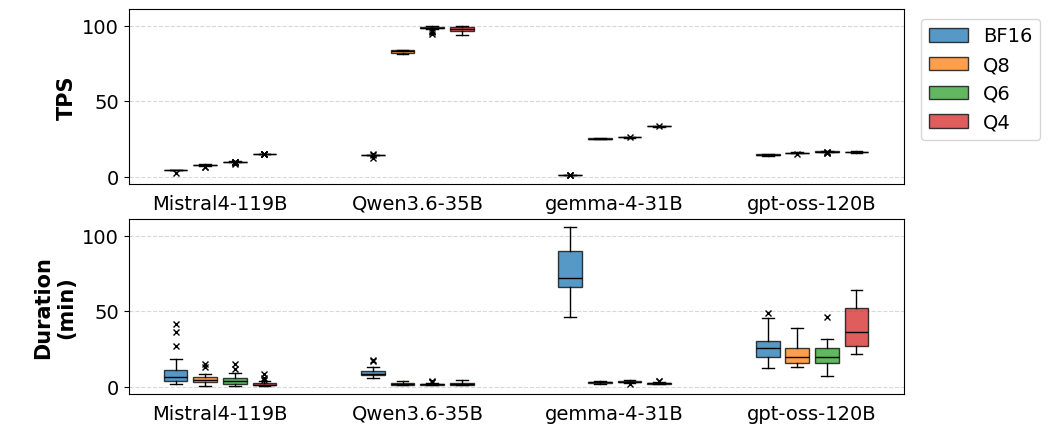

In [33]:
fig, ax = plt.subplots(2,1, figsize=(10, 5), sharey=True)
plot_data_boxplot(df_task2, 'tokens_per_second', ax=ax[0], ylabel='TPS', show_legend=True)
plot_data_boxplot(df_task2, 'duration_min',     ax=ax[1], ylabel='Duration\n(min)')


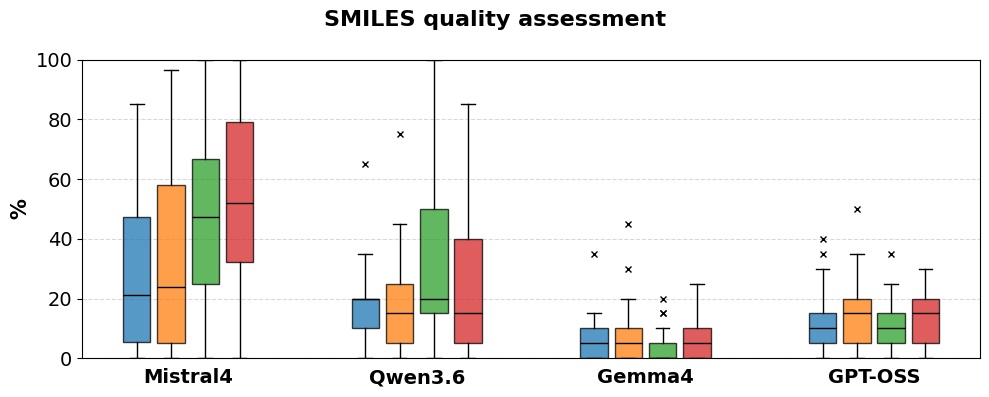

In [40]:
fig, ax = plt.subplots(1,1, figsize=(10, 4), sharex=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'pct_smi_invalid', ax=ax, title='', ylabel='%', ylim=[0,100], scale=100)
plt.tight_layout()
plt.show()
#plot_data_boxplot(df_task2, 'intdiv', ax=ax[3], ylabel='IntDiv', title=None, ylim=None, scale=1)


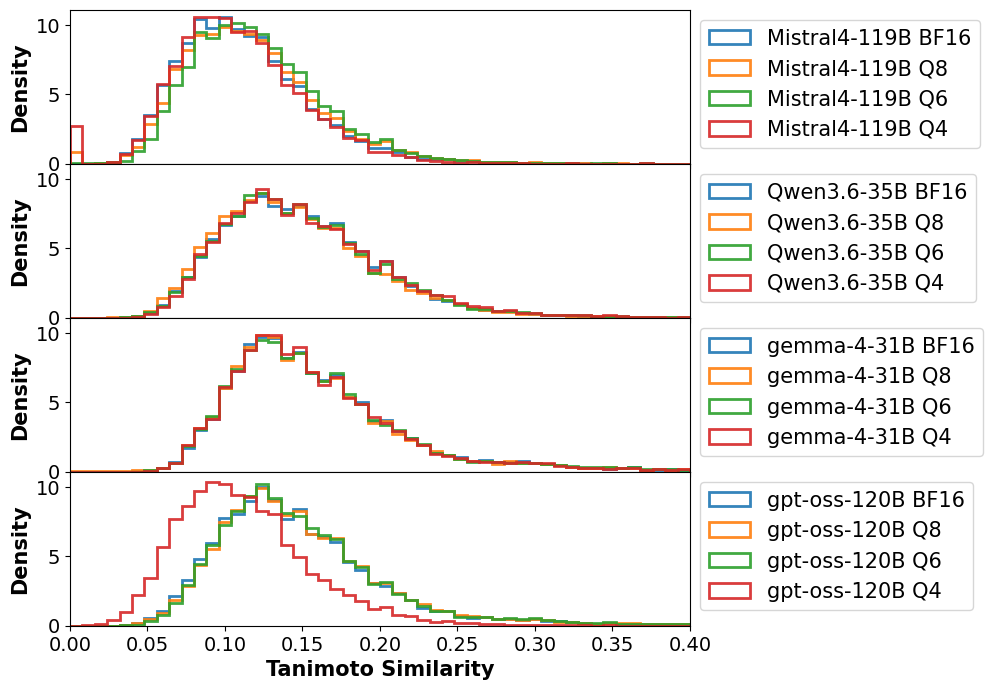

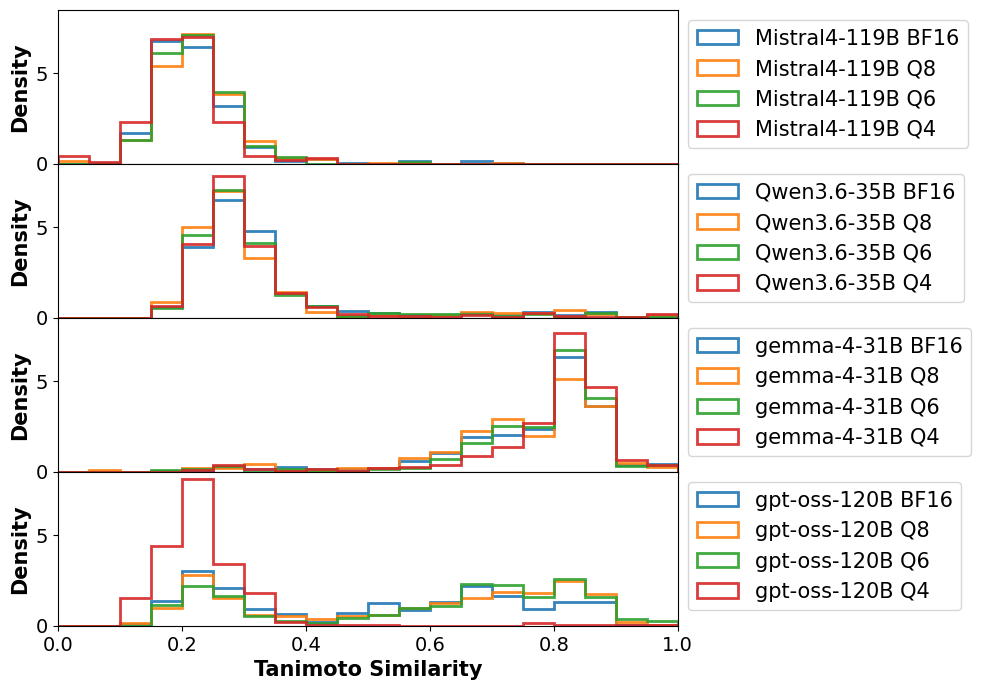

In [45]:
plot_data_histogram(df=df_task2, stat='sim all', xlim=[0,0.4], bins=50)
plot_data_histogram(df=df_task2, stat='sim max', bins=20)

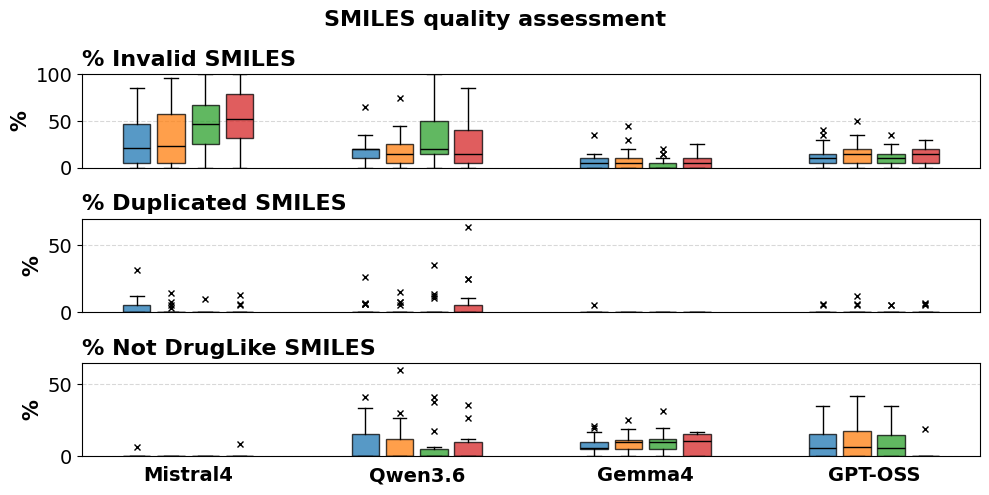

In [34]:
fig, ax = plt.subplots(3,1, figsize=(10, 5), sharex=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'pct_smi_invalid', ax=ax[0], title='% Invalid SMILES', ylabel='%', ylim=[0,100], scale=100)
plot_data_boxplot(df_task2, 'pct_smi_duplicated', ax=ax[1], title='% Duplicated SMILES', ylabel='%', ylim=[0,70], scale=100, show_legend=False)
plot_data_boxplot(df_task2, 'pct_smi_notdruglike', ax=ax[2], title='% Not DrugLike SMILES', ylabel='%', ylim=[0,65], scale=100, show_legend=False)
plt.tight_layout()
plt.show()
#plot_data_boxplot(df_task2, 'intdiv', ax=ax[3], ylabel='IntDiv', title=None, ylim=None, scale=1)


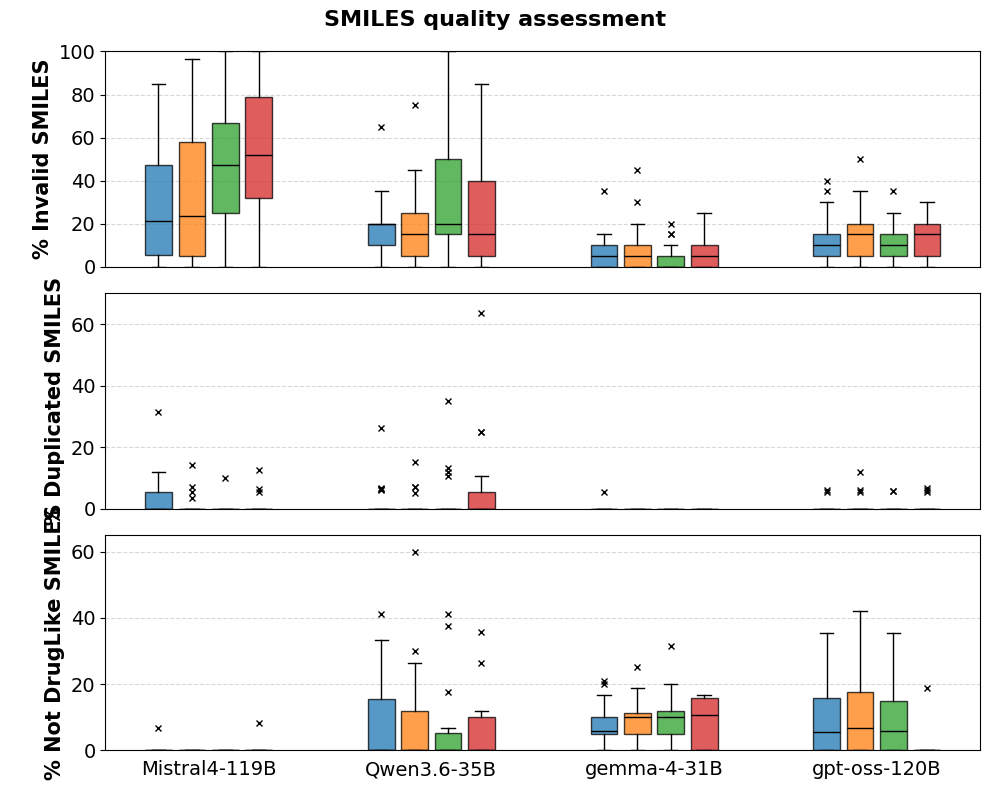

In [39]:
fig, ax = plt.subplots(3,1, figsize=(10, 8), sharex=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'pct_smi_invalid', ax=ax[0], ylabel='% Invalid SMILES', ylim=[0,100], scale=100)
plot_data_boxplot(df_task2, 'pct_smi_duplicated', ax=ax[1], ylabel='% Duplicated SMILES', ylim=[0,70], scale=100, show_legend=False)
plot_data_boxplot(df_task2, 'pct_smi_notdruglike', ax=ax[2], ylabel='% Not DrugLike SMILES', ylim=[0,65], scale=100, show_legend=False)
plt.tight_layout()
plt.show()
#plot_data_boxplot(df_task2, 'intdiv', ax=ax[3], ylabel='IntDiv', title=None, ylim=None, scale=1)



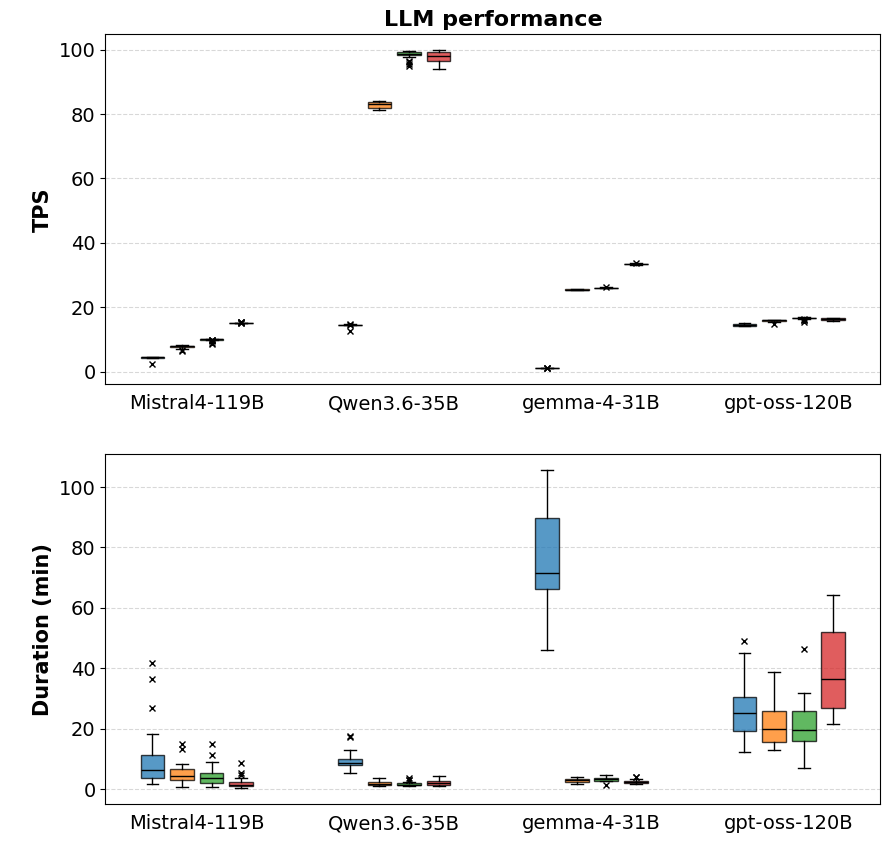

In [40]:
fig, ax = plt.subplots(2,1, figsize=(10, 10))
ax[0].set_title('LLM performance', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'tokens_per_second', ax=ax[0], ylabel='TPS', ylim=None, scale=1)
plot_data_boxplot(df_task2, 'duration_min', ax=ax[1], ylabel='Duration (min)', title=None, ylim=None, scale=1)
plt.show()
#plot_data_boxplot(df_task2, 'intdiv', ax=ax[3], ylabel='IntDiv', title=None, ylim=None, scale=1)



### **TASK 2** - UMAP fitado no prompt

>> UMAP fitado APENAS NAS MOLÉCULAS DE REFERÊNCIA (prompt) <<
N_NEIGHBORS = 3
MIN_DIST    = 0.0001


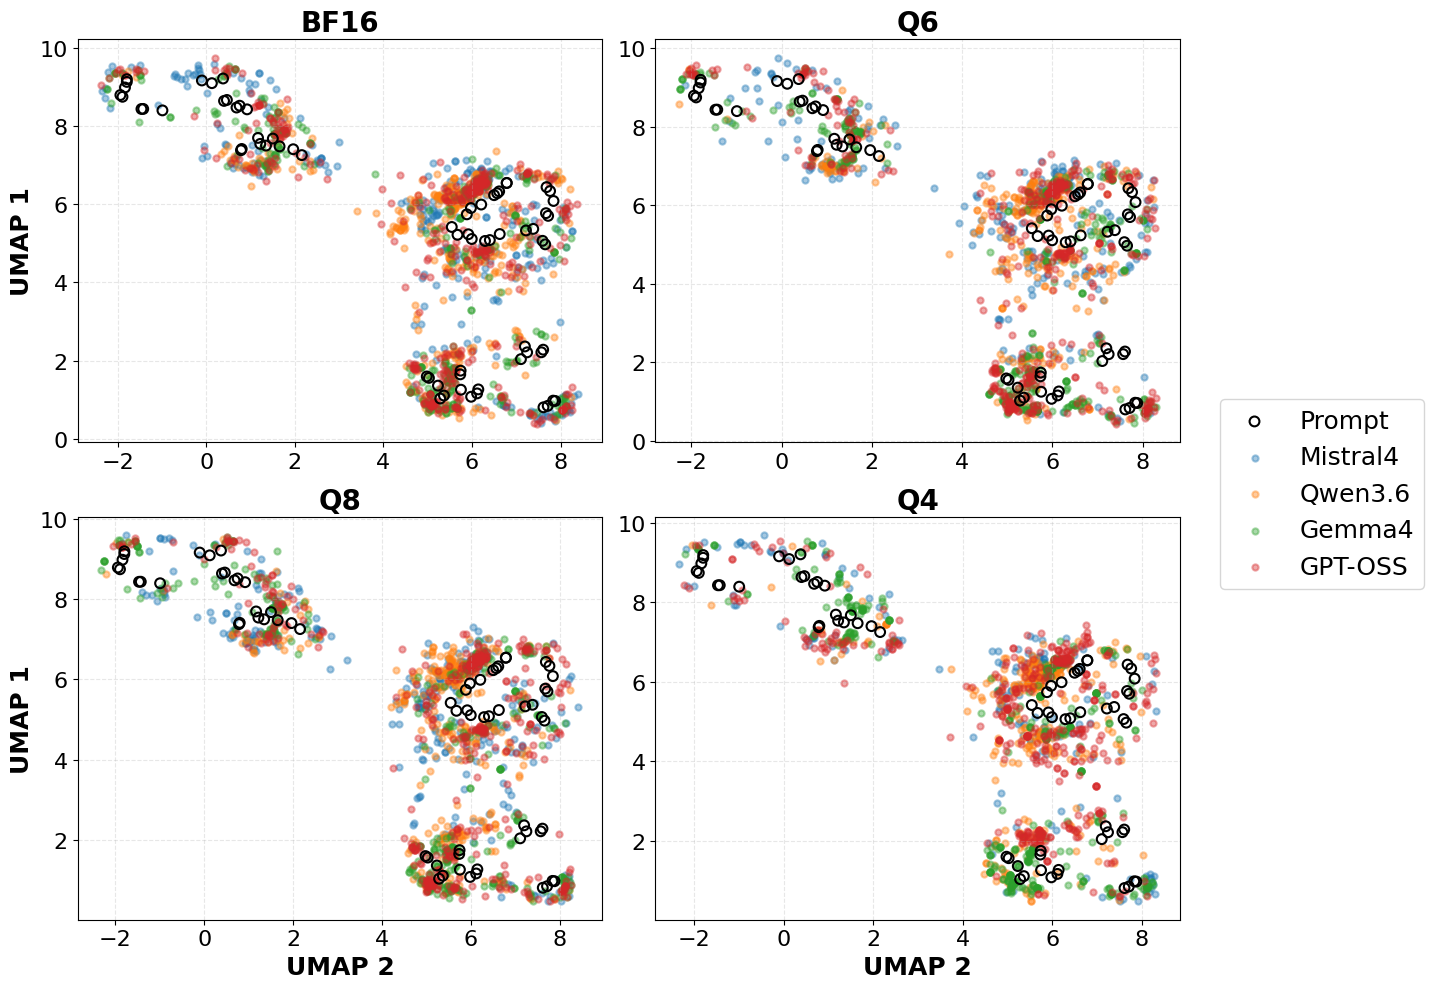


>> UMAP fitado APENAS NAS MOLÉCULAS DE REFERÊNCIA (prompt) <<
N_NEIGHBORS = 3
MIN_DIST    = 0.015


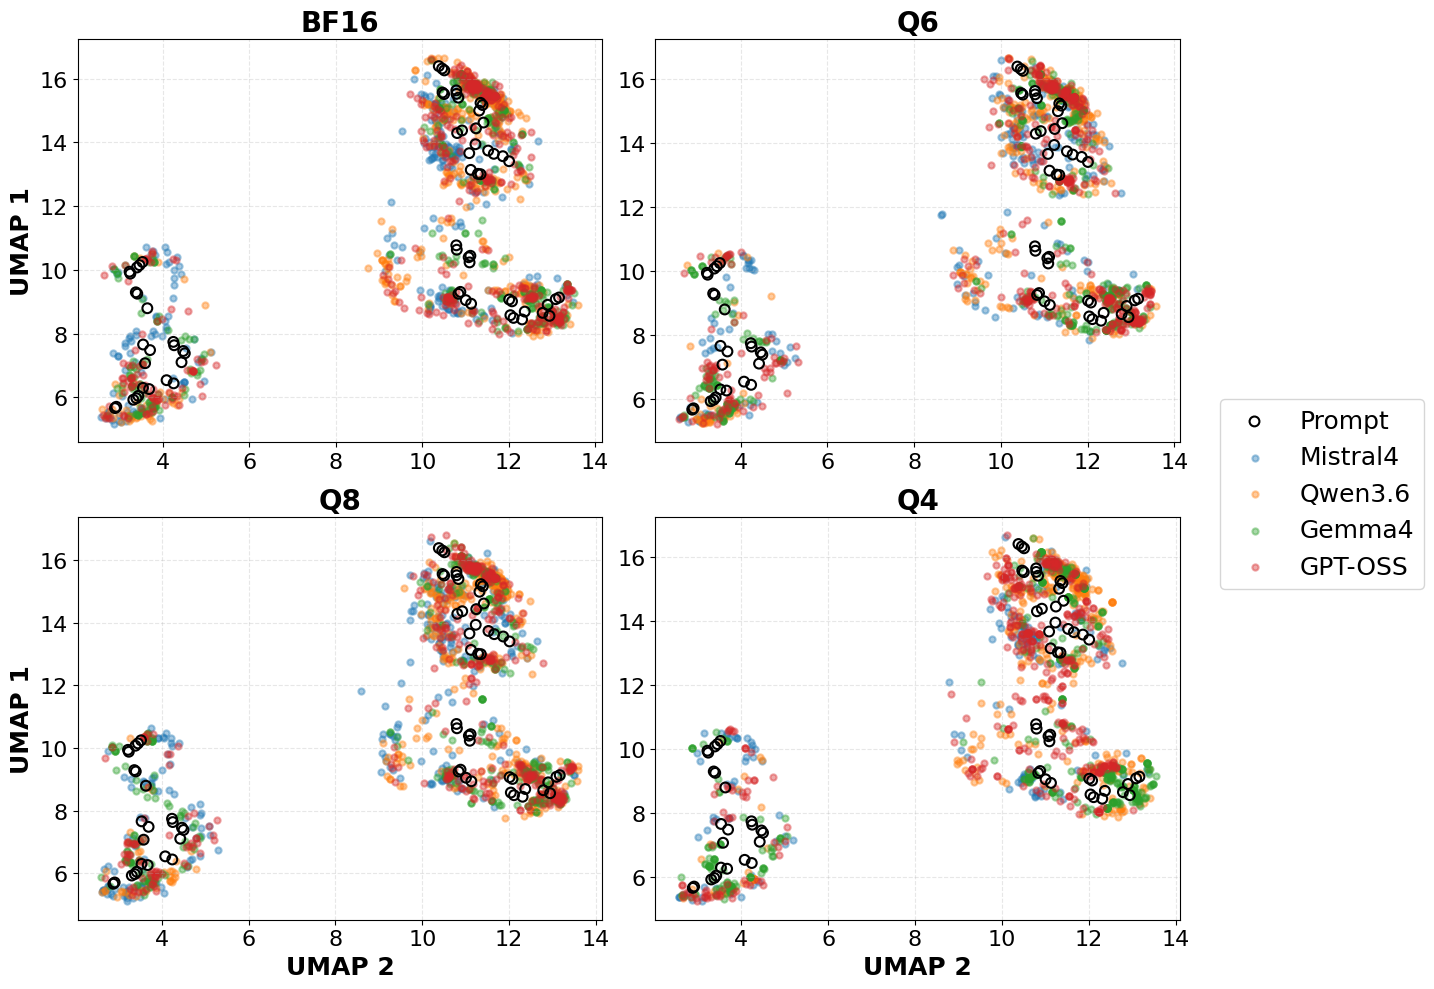

In [280]:
for min_dist in [0.0001, 0.0150]:
    for n_neighbors in [3]:
        print('='*70)
        print('>> UMAP fitado APENAS NAS MOLÉCULAS DE REFERÊNCIA (prompt) <<')
        print('N_NEIGHBORS =', n_neighbors)
        print('MIN_DIST    =', min_dist)

        tmp = calc_umap_fit_prompt(df=df_task2, n_neighbors=n_neighbors, min_dist=min_dist)
        plot_umap(tmp, prompt=True, split_prompt_by_quant=False)
        print()

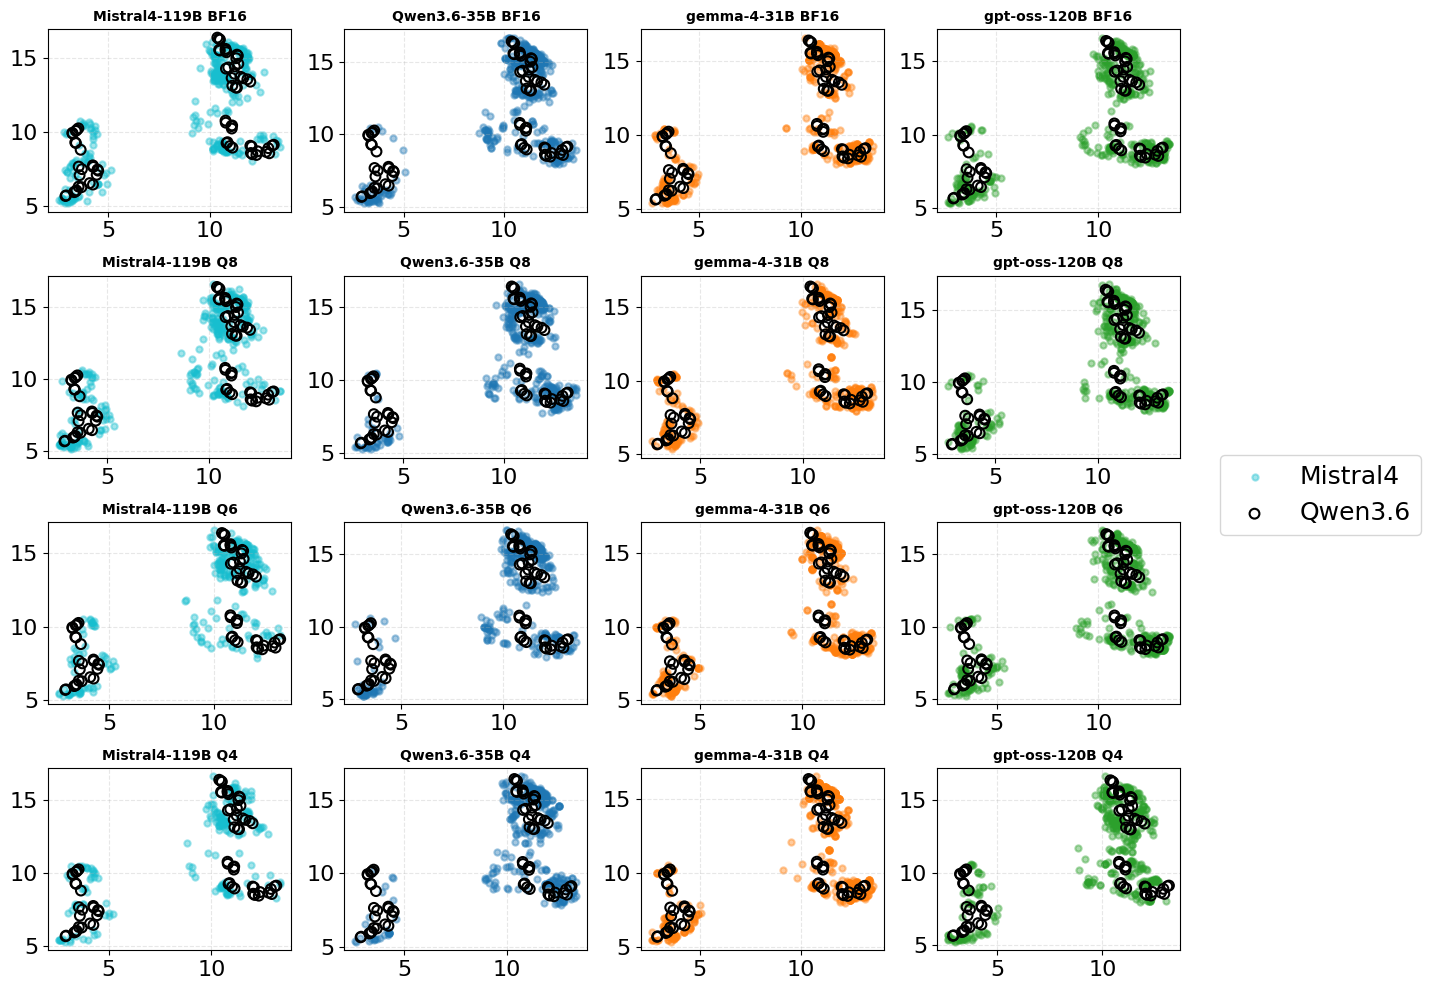

In [307]:
tmp_ = calc_umap_fit_prompt(df=df_task2, n_neighbors=3, min_dist=0.015)
plot_umap2(tmp_)

### **TASK 2** - UMAP fitado em prompt + cada quantização

>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 0.05


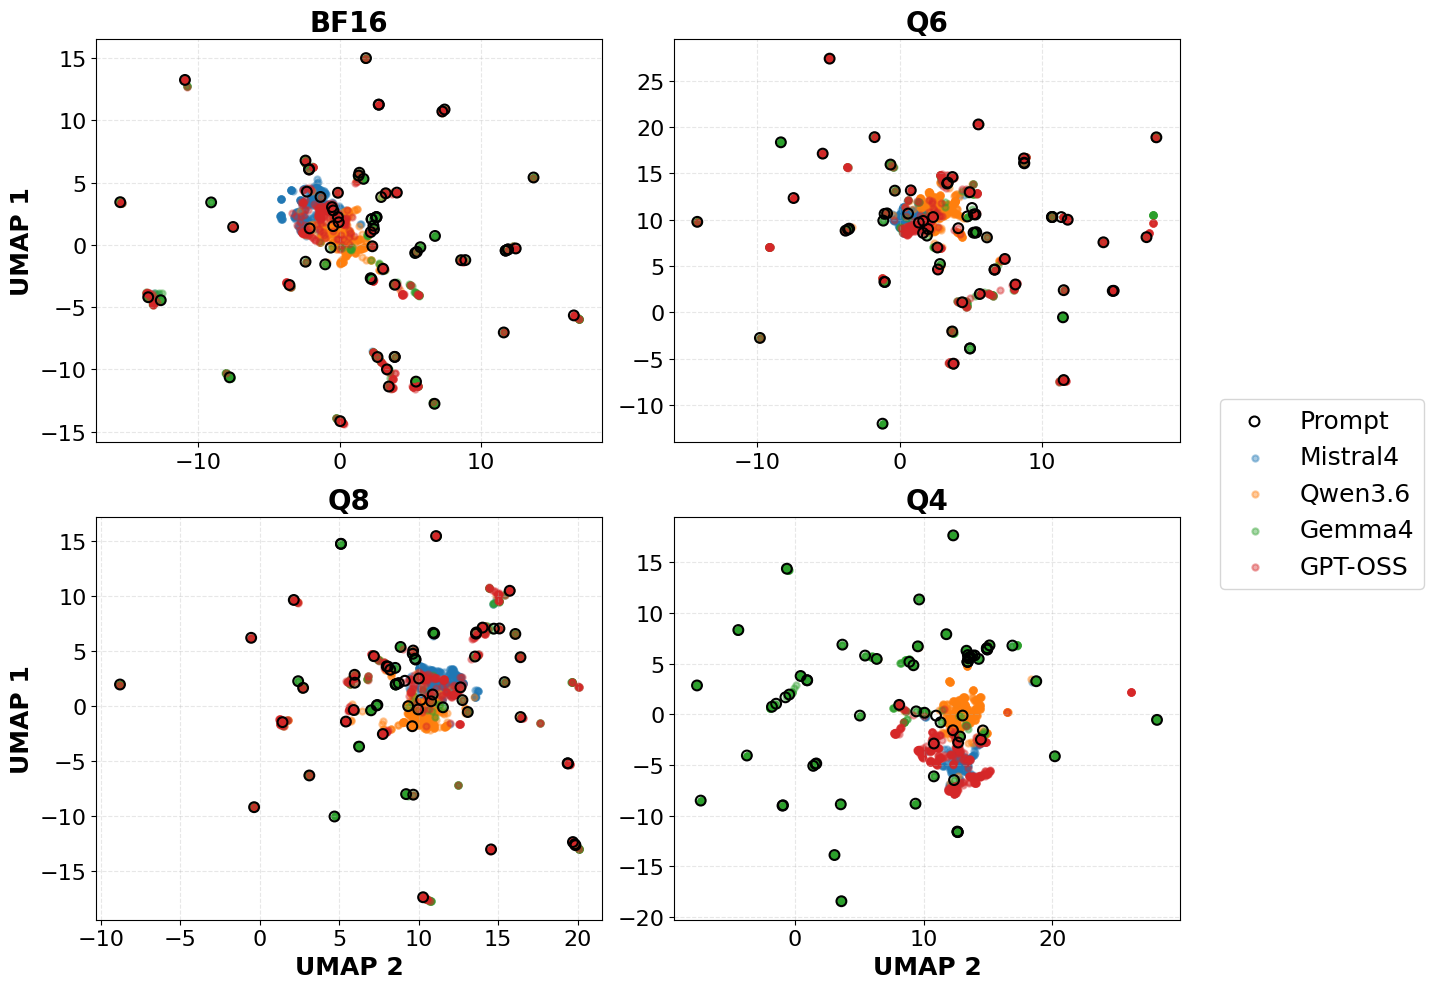


>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 0.1


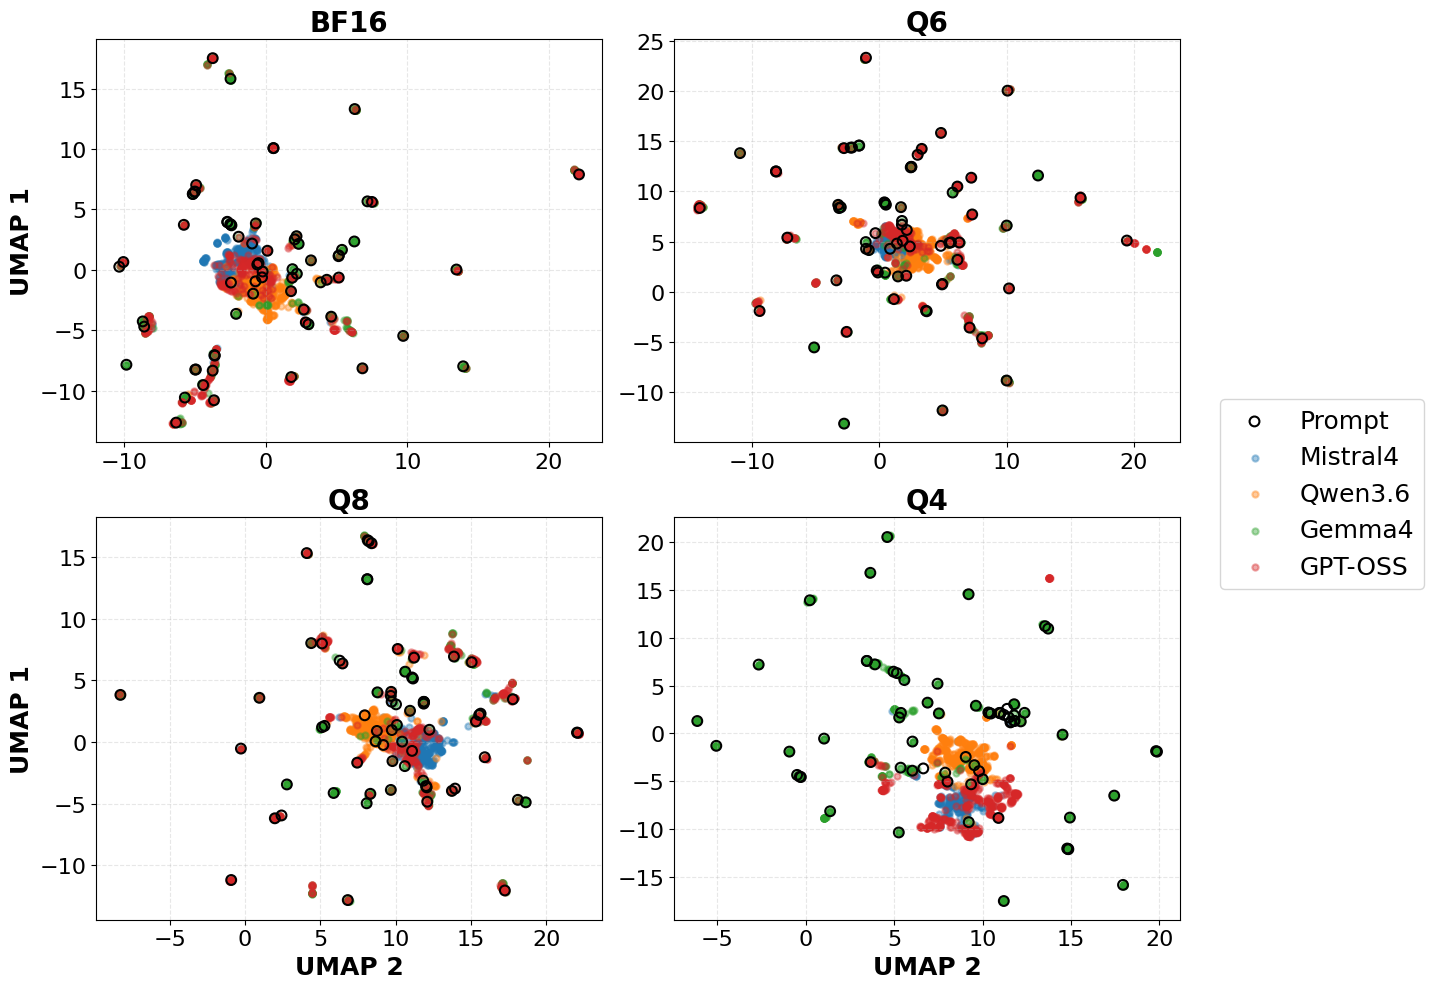


>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 0.3


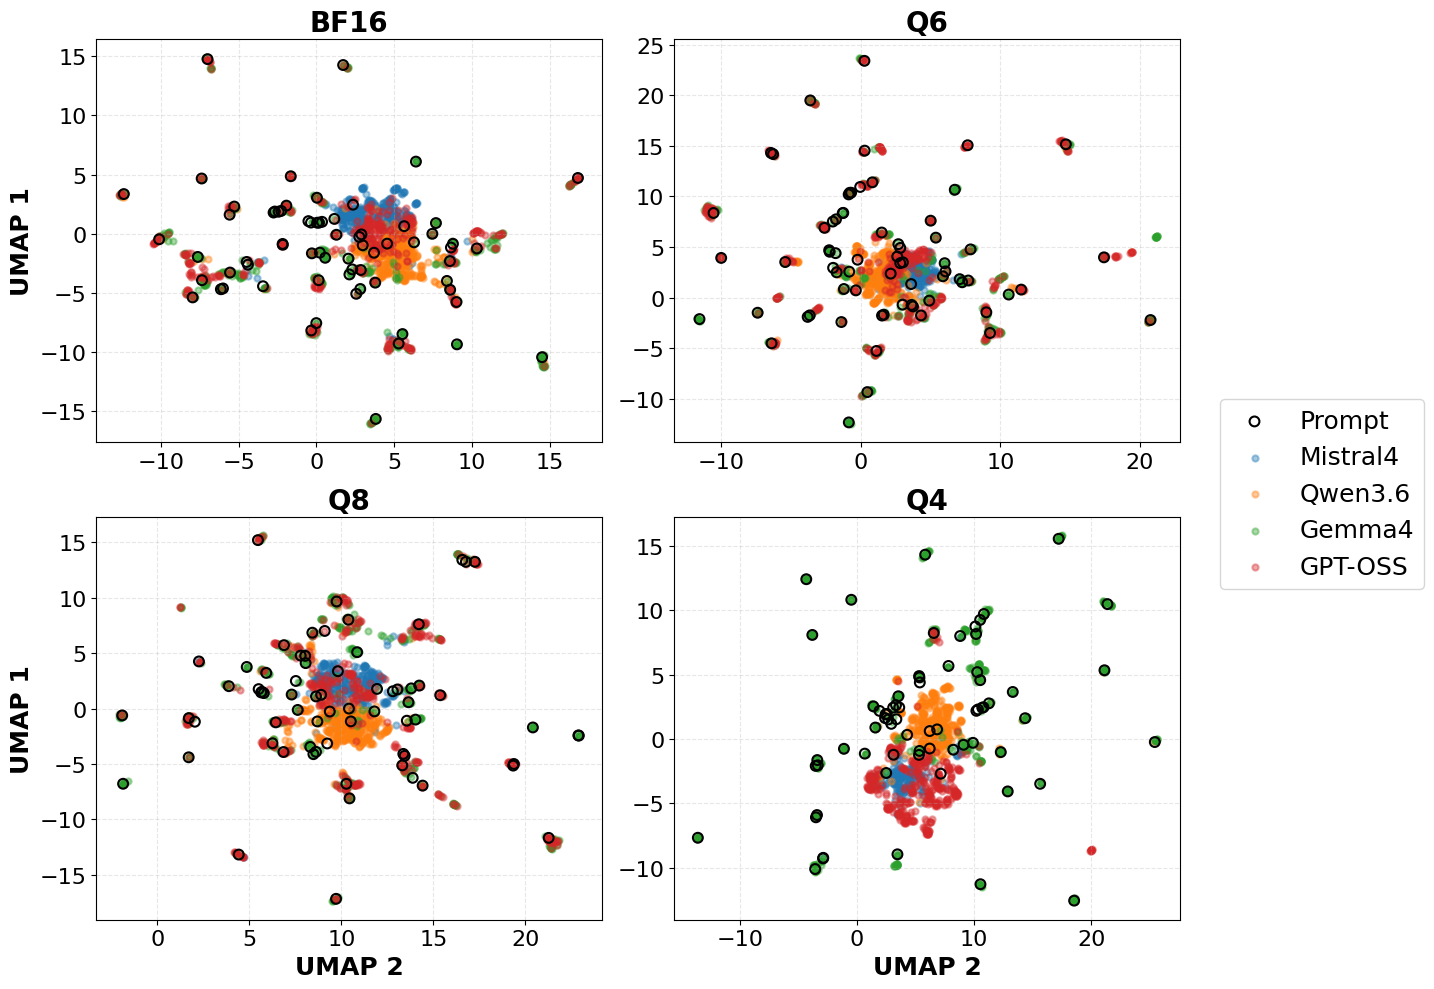


>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 15
MIN_DIST    = 0.05


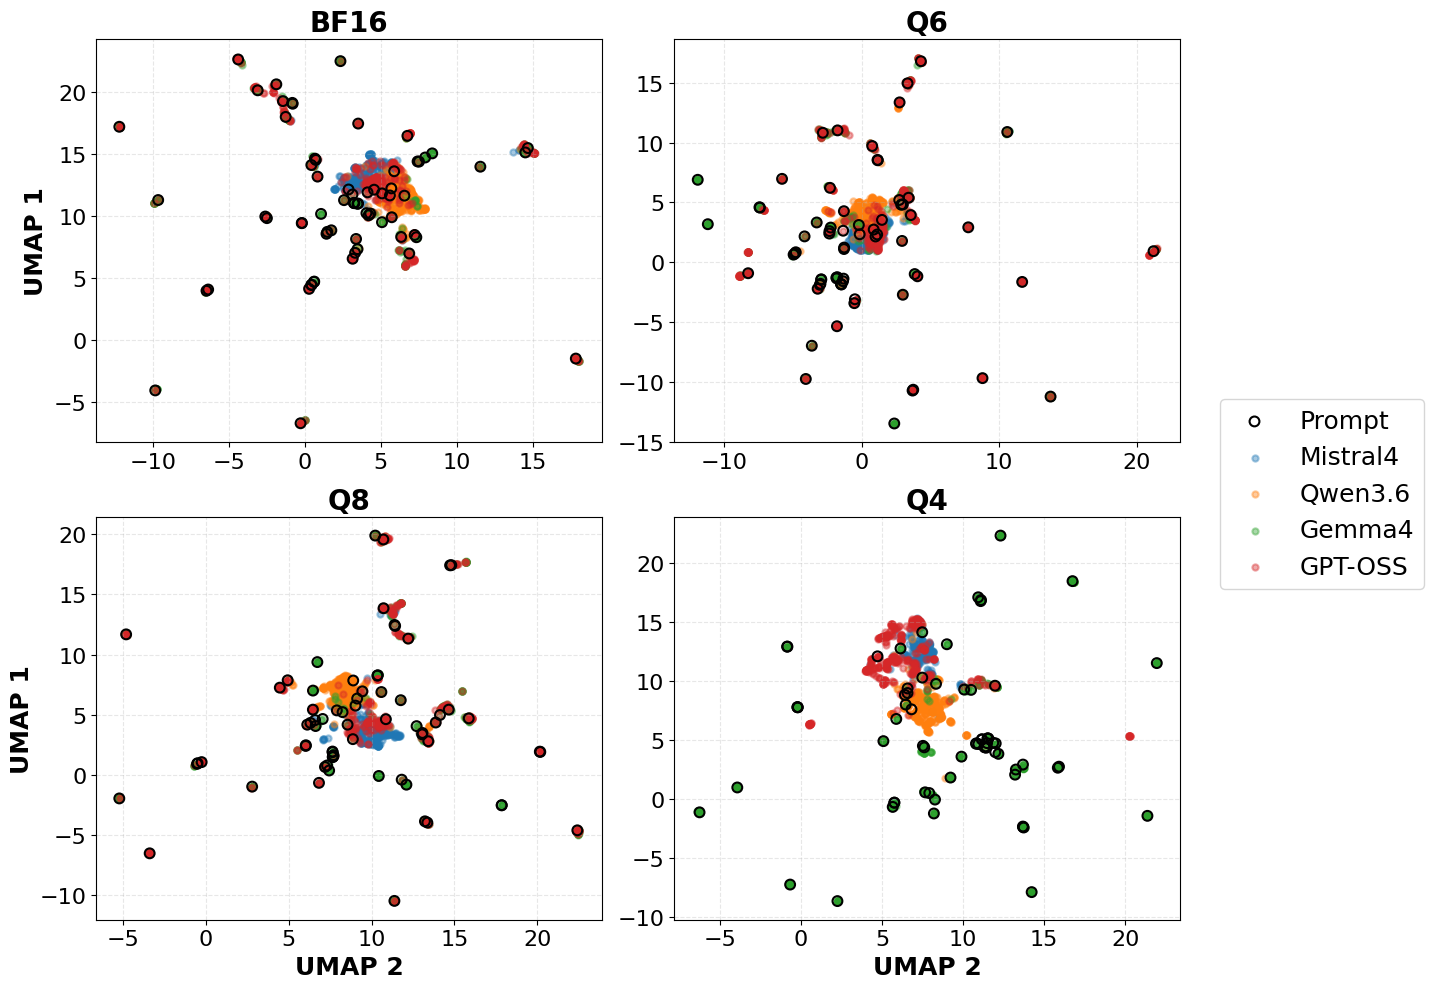


>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 15
MIN_DIST    = 0.1


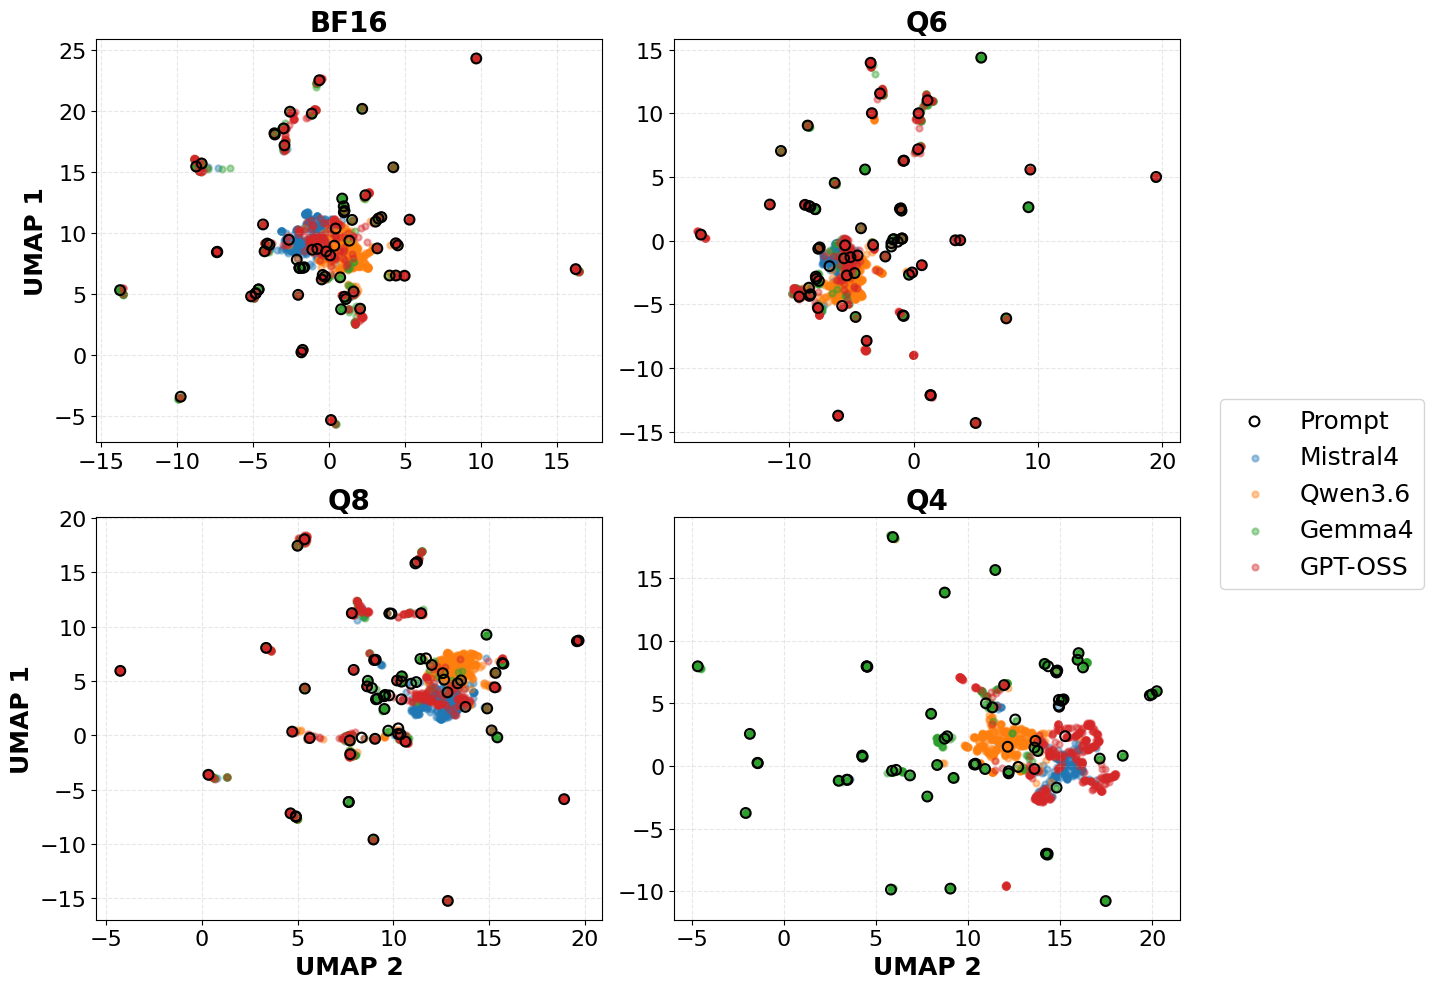


>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 15
MIN_DIST    = 0.3


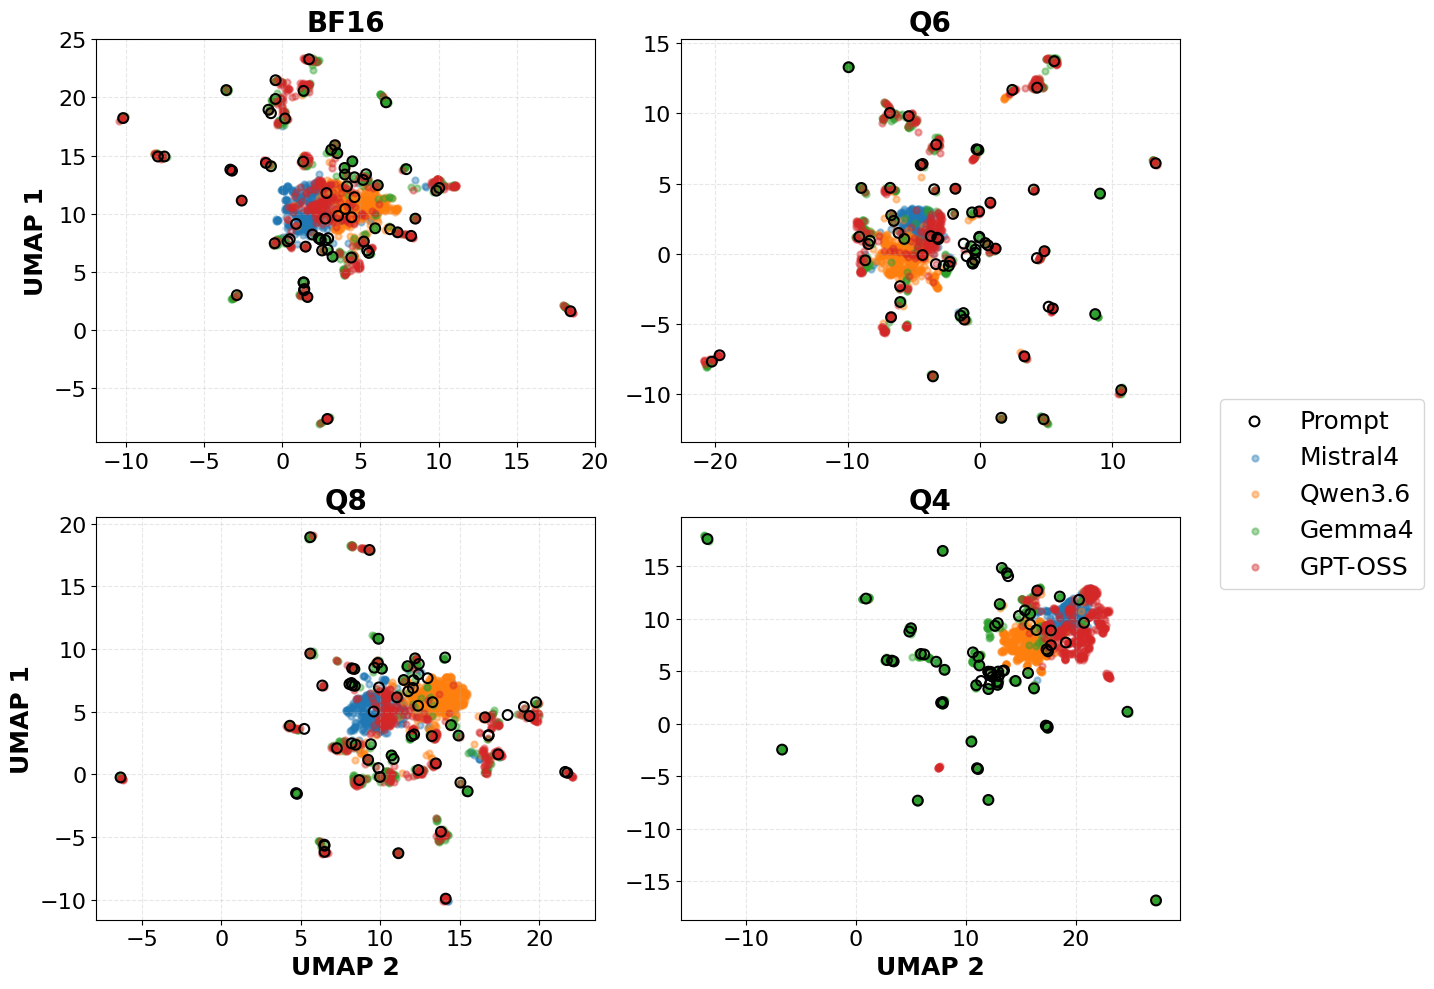

In [282]:
for n_neighbors in [10, 15]:
    for min_dist in [0.05, 0.10, 0.30]:
        print('='*70)
        print('>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<')
        print('N_NEIGHBORS =', n_neighbors)
        print('MIN_DIST    =', min_dist)

        tmp = calc_umap_quant(df=df_task2, n_neighbors=n_neighbors, min_dist=min_dist, prompt=True)
        plot_umap(tmp, prompt=True, split_prompt_by_quant=True)
        print()

### **TASK 2** - UMAP fitado em todas as moléculas

>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 0.3


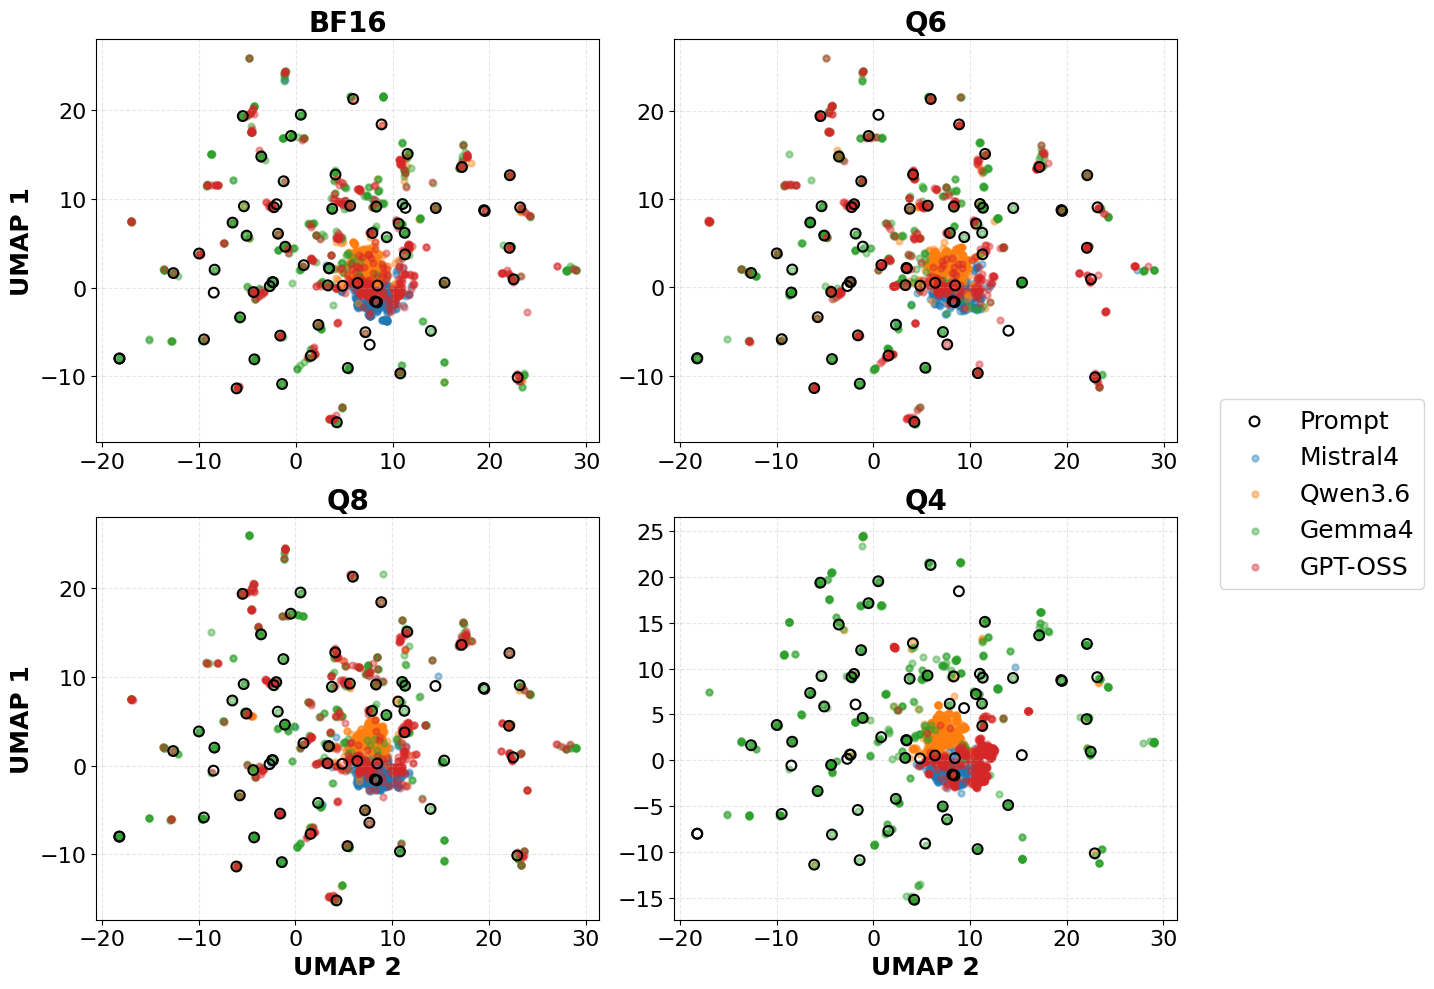

>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 0.6


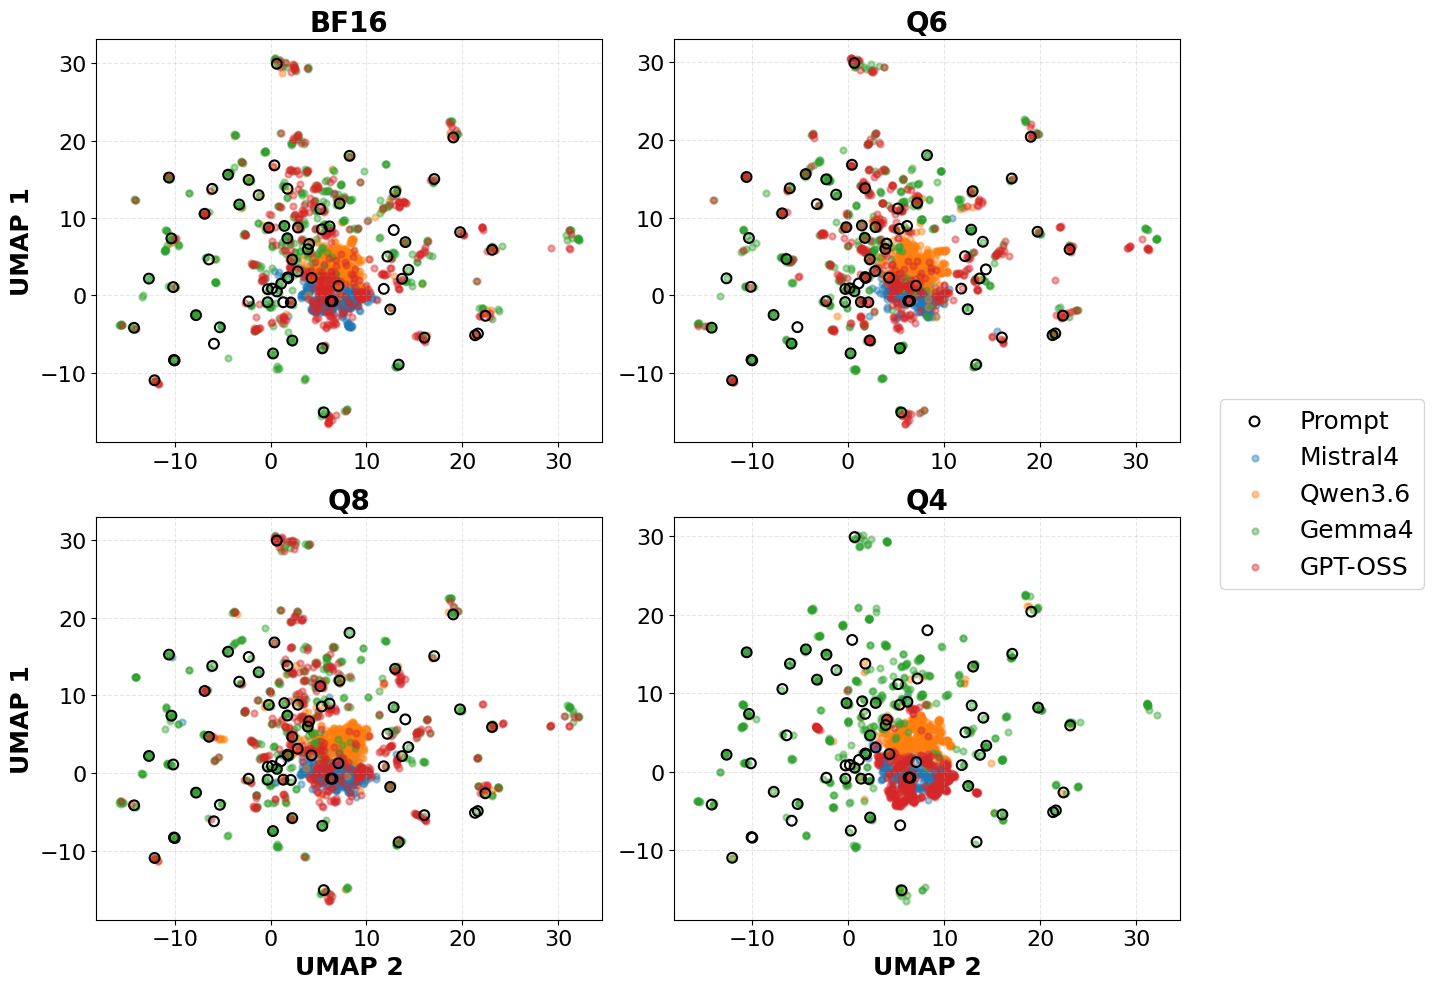

>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<
N_NEIGHBORS = 10
MIN_DIST    = 1.0


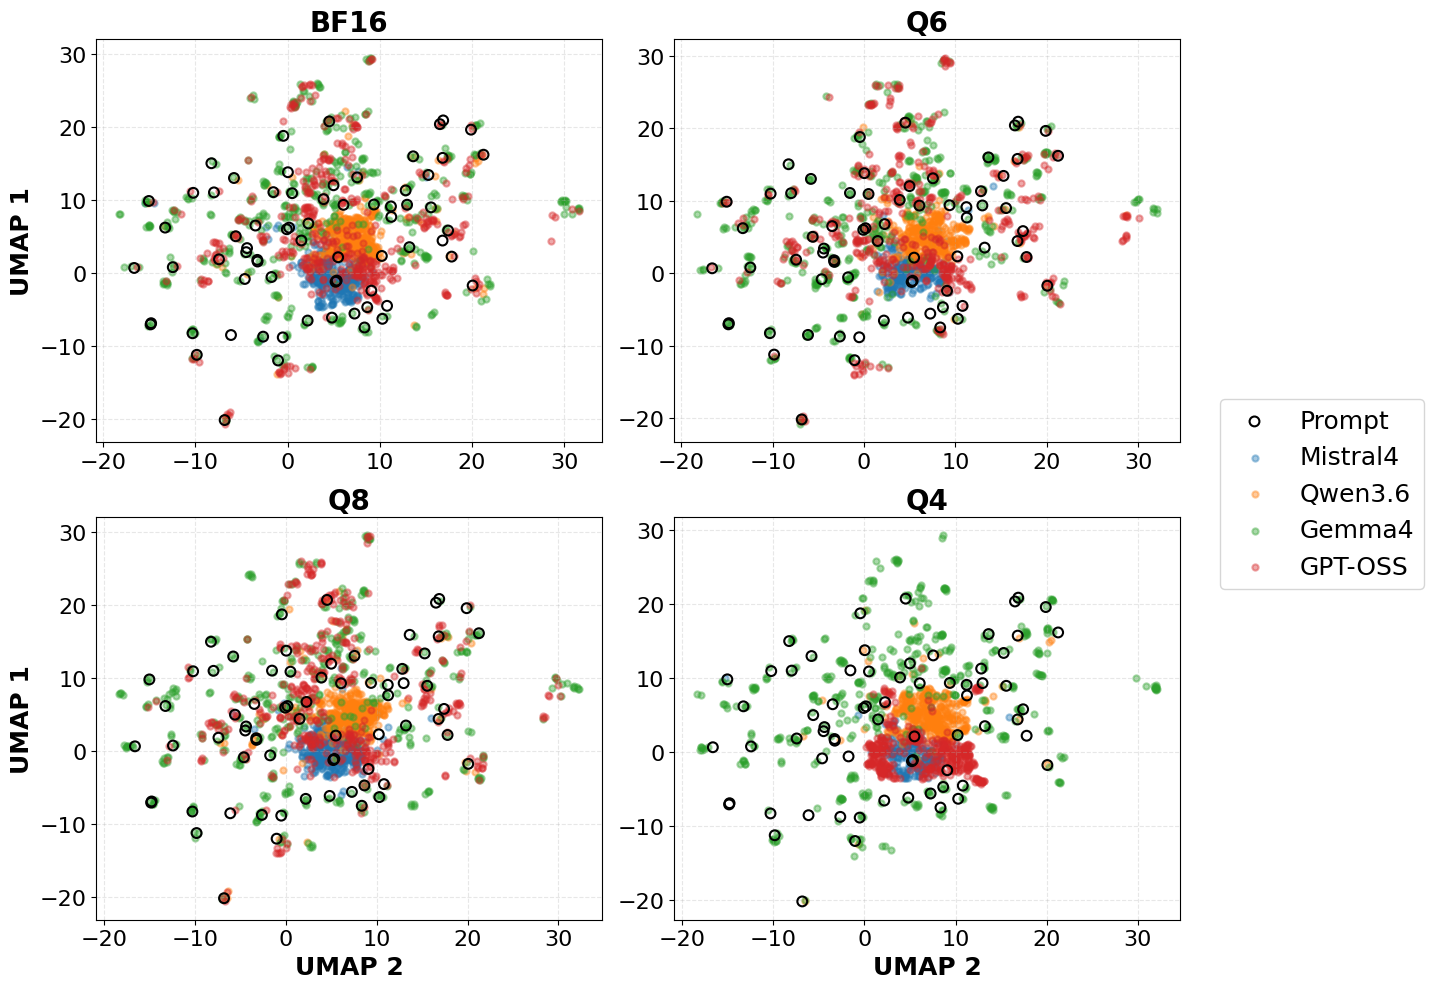

In [261]:
for min_dist in [0.3, 0.6, 1.0]:
    for n_neighbors in [10]:
        print('='*70)
        print('>> UMAP fitado TODAS AS MOLÉCULAS (prompt+geradas) <<')
        print('N_NEIGHBORS =', n_neighbors)
        print('MIN_DIST    =', min_dist)

        tmp = calc_umap_all(df=df_task2, n_neighbors=n_neighbors, min_dist=min_dist, prompt=True)
        plot_umap(tmp, prompt=True, split_prompt_by_quant=False)

----

# **FIGURAS** - TASK1

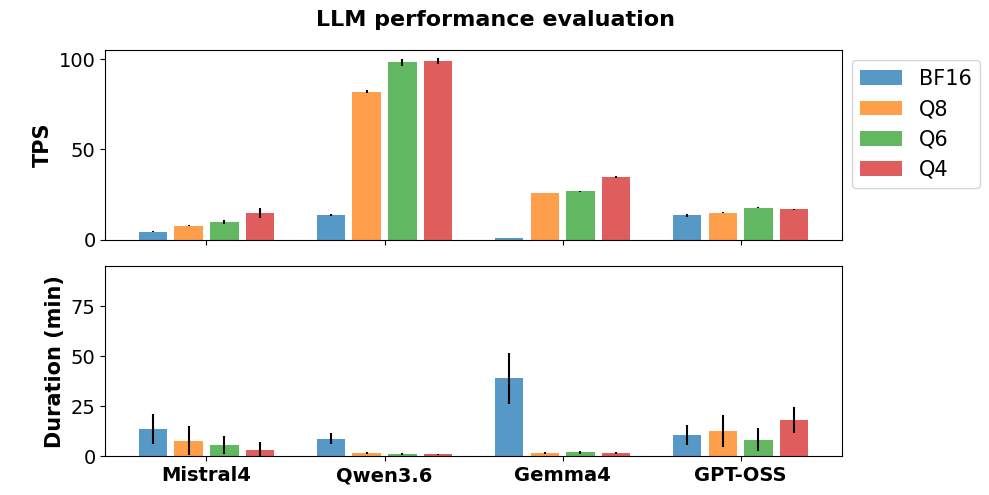

In [35]:
fig, ax = plt.subplots(2,1, figsize=(10, 5), sharex=True)
fig.suptitle('LLM performance evaluation', fontsize=16, fontweight='bold')
plot_data(d_stats=d_stats_task1, stat='tokens_per_second', ax=ax[0], ylabel='TPS'           , ylim=[0,105], prompt_avg=None, prompt_std=0.0, scale=1, show_legend=True)
plot_data(d_stats=d_stats_task1, stat='duration_min',      ax=ax[1], ylabel='Duration (min)'  , ylim=[0,95],  prompt_avg=None, prompt_std=0.0, scale=1)
plt.tight_layout()
plt.show()

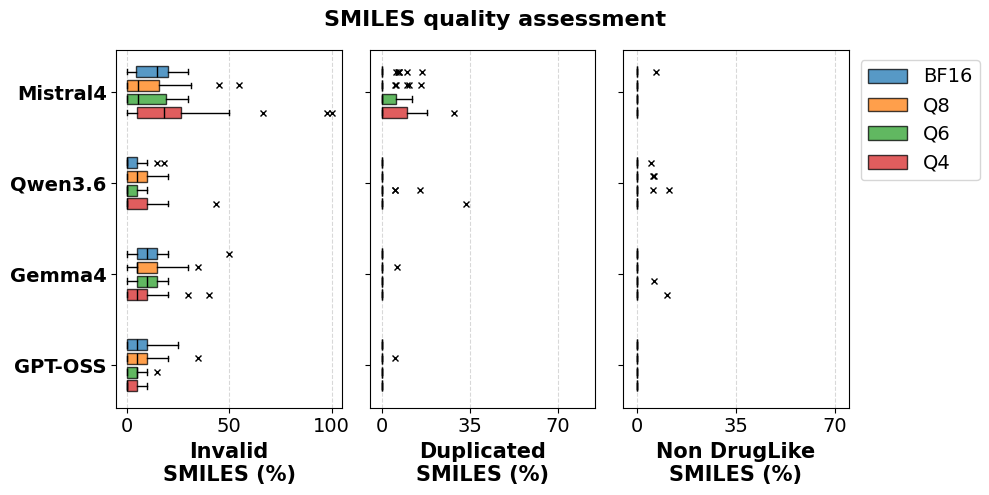

In [36]:
fig, ax = plt.subplots(1,3, figsize=(10, 5), sharey=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_hboxplot(df_task1, 'pct_smi_invalid', ax=ax[0], ylabel='Invalid\nSMILES (%)', xlim=[-5,105], xticks=[0,50,100], scale=100, show_legend=False)
plot_data_hboxplot(df_task1, 'pct_smi_duplicated', ax=ax[1], ylabel='Duplicated\nSMILES (%)', xlim=[-5,85], xticks=[0,35,70], scale=100, show_legend=False)
plot_data_hboxplot(df_task1, 'pct_smi_notdruglike', ax=ax[2], ylabel='Non DrugLike\nSMILES (%)', xlim=[-5,75], xticks=[0,35,70], scale=100, show_legend=True)
plt.tight_layout()
plt.show()

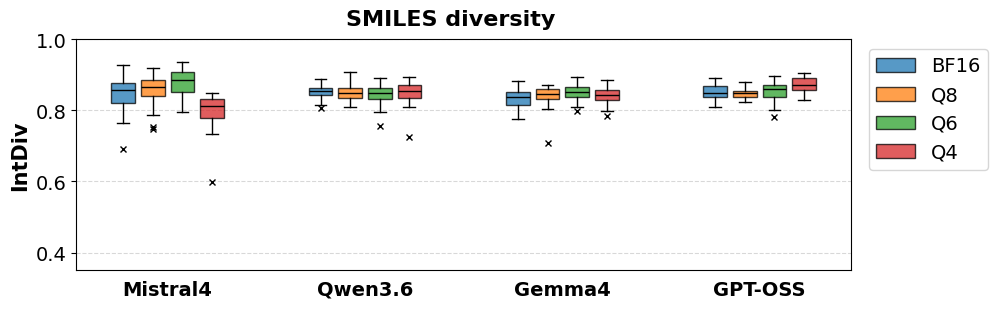

In [37]:
fig, ax = plt.subplots(1,1, figsize=(10, 3), sharey=True)
fig.suptitle('SMILES diversity', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task1, 'intdiv', ax=ax, ylabel='IntDiv', show_legend=True, ylim=[0.35, 1.00])
#fig.show()

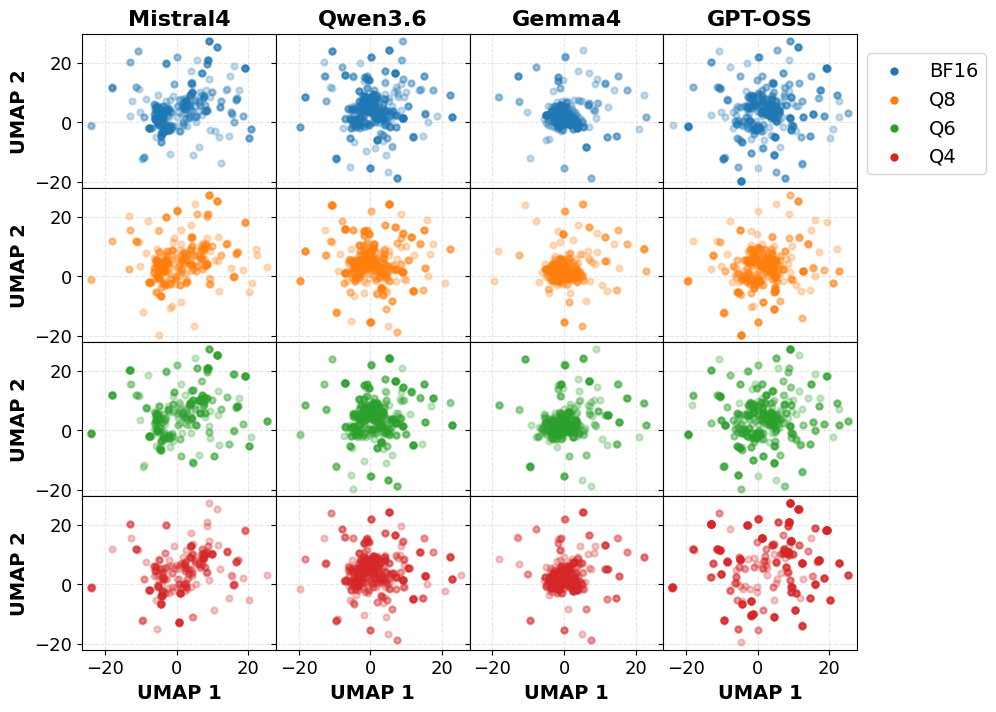

In [150]:
plot_umap_grid(df_task1_umap_all, prompt=False)

# **FIGURAS** - TASK2

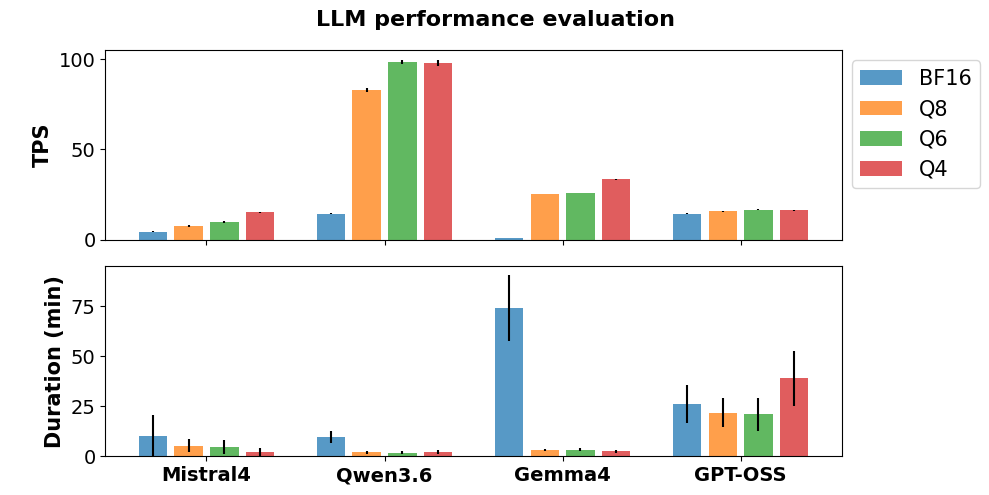

In [38]:
fig, ax = plt.subplots(2,1, figsize=(10, 5), sharex=True)
fig.suptitle('LLM performance evaluation', fontsize=16, fontweight='bold')
plot_data(d_stats=d_stats_task2, stat='tokens_per_second', ax=ax[0], ylabel='TPS'           , ylim=[0,105], prompt_avg=None, prompt_std=0.0, scale=1, show_legend=True)
plot_data(d_stats=d_stats_task2, stat='duration_min',      ax=ax[1], ylabel='Duration (min)'  , ylim=[0,95],  prompt_avg=None, prompt_std=0.0, scale=1)
plt.tight_layout()
plt.show()

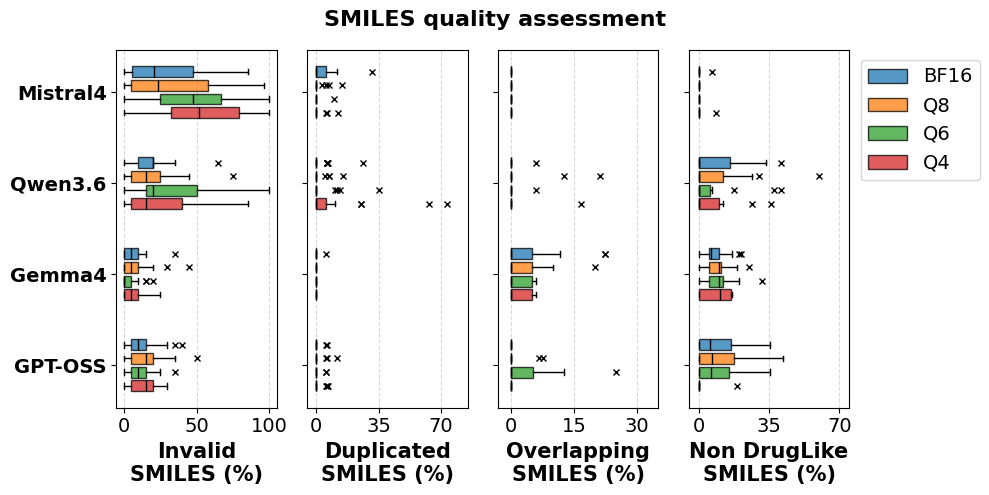

In [39]:
fig, ax = plt.subplots(1,4, figsize=(10, 5), sharey=True)
fig.suptitle('SMILES quality assessment', fontsize=16, fontweight='bold')
plot_data_hboxplot(df_task2, 'pct_smi_invalid',     ax=ax[0], ylabel='Invalid\nSMILES (%)',      xlim=[-5,105], xticks=[0,50,100], scale=100, show_legend=False)
plot_data_hboxplot(df_task2, 'pct_smi_duplicated',  ax=ax[1], ylabel='Duplicated\nSMILES (%)',   xlim=[-5,85],  xticks=[0,35,70],  scale=100, show_legend=False)
plot_data_hboxplot(df_task2, 'pct_smi_overlap',     ax=ax[2], ylabel='Overlapping\nSMILES (%)',  xlim=[-3,35],  xticks=[0,15,30],  scale=100, show_legend=False)
plot_data_hboxplot(df_task2, 'pct_smi_notdruglike', ax=ax[3], ylabel='Non DrugLike\nSMILES (%)', xlim=[-5,75],  xticks=[0,35,70],  scale=100, show_legend=True)
plt.tight_layout()
plt.show()

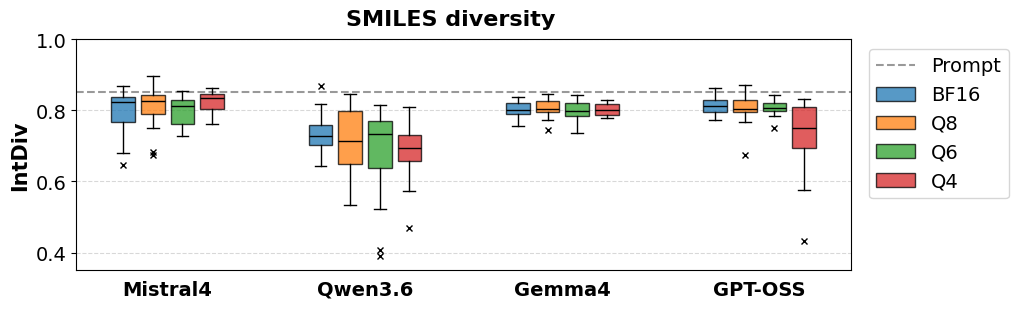

In [40]:
fig, ax = plt.subplots(1,1, figsize=(10, 3), sharey=True)
fig.suptitle('SMILES diversity', fontsize=16, fontweight='bold')
plot_data_boxplot(df_task2, 'intdiv', ax=ax, ylabel='IntDiv', show_legend=True, ylim=[0.35, 1.00], prompt=d_prompt['intdiv'])
#fig.show()

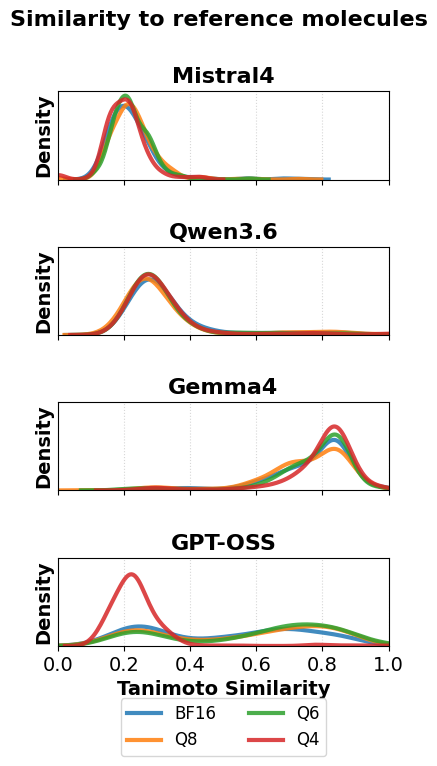

In [38]:
fig, ax = plt.subplots(4, 1, figsize=(4, 8), sharey=True, sharex=True)
fig.suptitle('Similarity to reference molecules', fontsize=16, fontweight='bold')

i=0
for model,label in zip(lst_models, lst_models_labels):
    if i==len(lst_models)-1:
        show_legend = True
    else:
        show_legend = False
        
    plot_data_kde(df_task2, model, label, stat='sim max', ax=ax[i], show_legend=show_legend)
    i+=1
plt.tight_layout()


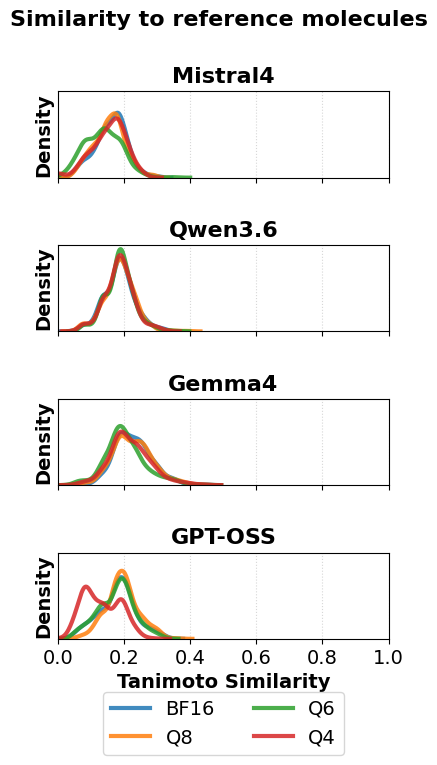

In [60]:
fig, ax = plt.subplots(4, 1, figsize=(4, 8), sharey=True, sharex=True)
fig.suptitle('Similarity to reference molecules', fontsize=16, fontweight='bold')

i=0
for model,label in zip(lst_models, lst_models_labels):
    if i==len(lst_models)-1:
        show_legend = True
    else:
        show_legend = False
        
    plot_data_kde(df_task1, model, label, stat='sim max', ax=ax[i], show_legend=show_legend)
    i+=1
plt.tight_layout()


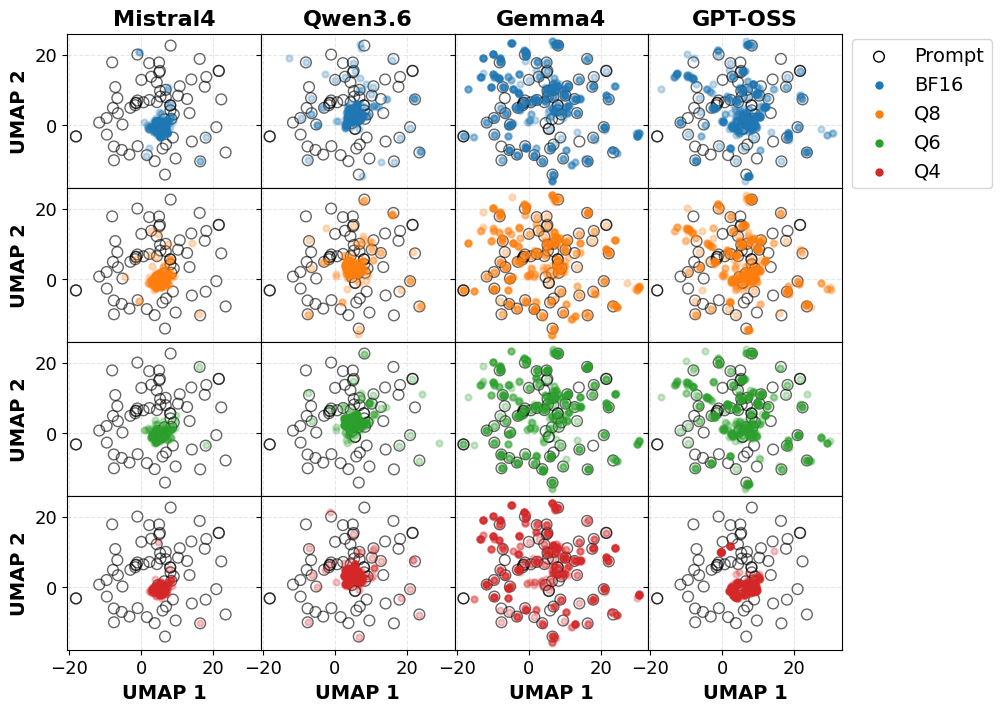

In [154]:
plot_umap_grid(df_task2_umap_all, prompt=True)

In [60]:
stat='duration_min'

for m in d_stats_task1:
    for q in d_stats_task1[m]:
        v = d_stats_task1[m][q][stat]['avg']*100
        print(f'{m:14s} {q:4s} {v:5.2f}')

Mistral4-119B  BF16 1376.47
Mistral4-119B  Q8   769.93
Mistral4-119B  Q6   579.33
Mistral4-119B  Q4   332.95
Qwen3.6-35B    BF16 867.39
Qwen3.6-35B    Q8   153.35
Qwen3.6-35B    Q6   111.75
Qwen3.6-35B    Q4   106.16
gemma-4-31B    BF16 3909.40
gemma-4-31B    Q8   163.09
gemma-4-31B    Q6   195.79
gemma-4-31B    Q4   149.88
gpt-oss-120B   BF16 1054.32
gpt-oss-120B   Q8   1245.75
gpt-oss-120B   Q6   823.39
gpt-oss-120B   Q4   1817.87


In [66]:
stat='duration_min'
m='Mistral4-119B'
print(((d_stats_task2[m]['BF16'][stat]['avg']/d_stats_task1[m]['BF16'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q8'][stat]['avg']/d_stats_task1[m]['Q8'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q6'][stat]['avg']/d_stats_task1[m]['Q6'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q4'][stat]['avg']/d_stats_task1[m]['Q4'][stat]['avg'])-0)*1)
print()
m='Qwen3.6-35B'
print(((d_stats_task2[m]['BF16'][stat]['avg']/d_stats_task1[m]['BF16'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q8'][stat]['avg']/d_stats_task1[m]['Q8'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q6'][stat]['avg']/d_stats_task1[m]['Q6'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q4'][stat]['avg']/d_stats_task1[m]['Q4'][stat]['avg'])-0)*1)
print()
m='gemma-4-31B'
print(((d_stats_task2[m]['BF16'][stat]['avg']/d_stats_task1[m]['BF16'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q8'][stat]['avg']/d_stats_task1[m]['Q8'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q6'][stat]['avg']/d_stats_task1[m]['Q6'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q4'][stat]['avg']/d_stats_task1[m]['Q4'][stat]['avg'])-0)*1)
print()
m='gpt-oss-120B'
print(((d_stats_task2[m]['BF16'][stat]['avg']/d_stats_task1[m]['BF16'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q8'][stat]['avg']/d_stats_task1[m]['Q8'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q6'][stat]['avg']/d_stats_task1[m]['Q6'][stat]['avg'])-0)*1)
print(((d_stats_task2[m]['Q4'][stat]['avg']/d_stats_task1[m]['Q4'][stat]['avg'])-0)*1)
print()

0.7536252640086855
0.6845755110505192
0.7998611968417966
0.6284650375652301

1.1201881872474182
1.2627139386093085
1.5906566610171615
1.9278322029640798

1.8974549333061943
1.8437093645696858
1.7114046153715197
1.6646922587999922

2.479969438674342
1.7487935611068555
2.5451522474531503
2.143254647170888



In [55]:
m='Qwen3.6-35B'
stat='pct_smi_invalid'
print(((d_stats_task1[m]['Q8'][stat]['avg']/d_stats_task1[m]['BF16']['tokens_per_second']['avg'])-1)*100)
print(((d_stats_task1[m]['Q6'][stat]['avg']/d_stats_task1[m]['Q8']['tokens_per_second']['avg'])-1)*100)
print(((d_stats_task1[m]['Q4'][stat]['avg']/d_stats_task1[m]['Q6']['tokens_per_second']['avg'])-1)*100)

-99.62647307516916
-99.97315151738496
-99.93732176786912


In [52]:
m='gemma-4-31B'
print(((d_stats_task1[m]['Q8']['tokens_per_second']['avg']/d_stats_task1[m]['BF16']['tokens_per_second']['avg'])-1)*100)
print(((d_stats_task1[m]['Q6']['tokens_per_second']['avg']/d_stats_task1[m]['Q8']['tokens_per_second']['avg'])-1)*100)
print(((d_stats_task1[m]['Q4']['tokens_per_second']['avg']/d_stats_task1[m]['Q6']['tokens_per_second']['avg'])-1)*100)

2328.7372437199438
3.1301743330822696
29.906489125848367


In [53]:
m='Mistral4-119B'
print(((d_stats_task1[m]['Q8']['tokens_per_second']['avg']/d_stats_task1[m]['BF16']['tokens_per_second']['avg'])-1)*100)
print(((d_stats_task1[m]['Q6']['tokens_per_second']['avg']/d_stats_task1[m]['Q8']['tokens_per_second']['avg'])-1)*100)
print(((d_stats_task1[m]['Q4']['tokens_per_second']['avg']/d_stats_task1[m]['Q6']['tokens_per_second']['avg'])-1)*100)

78.71348758605114
22.566535751342997
53.388655421694665


In [54]:
m='gpt-oss-120B'
print(((d_stats_task1[m]['Q8']['tokens_per_second']['avg']/d_stats_task1[m]['BF16']['tokens_per_second']['avg'])-1)*100)
print(((d_stats_task1[m]['Q6']['tokens_per_second']['avg']/d_stats_task1[m]['Q8']['tokens_per_second']['avg'])-1)*100)
print(((d_stats_task1[m]['Q4']['tokens_per_second']['avg']/d_stats_task1[m]['Q6']['tokens_per_second']['avg'])-1)*100)

10.348050995923884
18.990695749478114
-5.723234742878391
